<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-11/lab-066-density-matrices-noise.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 066. Density matrices, partial trace, measurement and noise

A register of two qubits can be in a single, fully known state vector while each of its qubits, looked at alone, behaves like a fair coin. We work out what a measurement on one part of the register predicts and what a measurement does to the rest of the register. We then follow the register when it leaks information to an environment we do not observe.

The register consists of two spins-1/2, qubit 0 and qubit 1. We prepare states with gates, evolve them with gates or with noise, and measure qubits in the $\hat Z$, $\hat X$ or $\hat Y$ basis. We compute measurement probabilities, the expectation values $\langle \hat Z\otimes \hat Z\rangle$ and $\langle \hat X\otimes \hat X\rangle$, the reduced state of one qubit, its purity and its entanglement entropy.

The first part introduces the density matrix of a pure state, a projector of rank one, and of a mixture, which differs from a superposition. We then treat the Bloch ball and write the classical correlated coin, a source of $|00\rangle$ or $|11\rangle$, as a density matrix. In the second part the partial trace is computed element by element, as a matrix product and as a tensor contraction. The purity and the entanglement entropy follow for a product state, a Bell state and the family $\cos\theta|00\rangle+\sin\theta|11\rangle$.

Measurement and noise form the third part. Projective measurement and its back-action come first, followed by an unread measurement as dephasing and by general measurements. We then derive noise channels from a coupled environment and apply six error models of a qubit to the register. The part closes with the standard noise model of quantum circuits, applied to a GHZ preparation. Sections 0 to 11 form the core route, and Section 12 adds the fidelity and the trace distance between general states.

Qubit 0 is the most significant bit, so the amplitude of the bit string $b_0b_1$ sits at index $2b_0+b_1$.

## 0. Double-precision arithmetic

We use JAX in double precision on the CPU, which is fast enough for registers of a few qubits, and NumPy and Matplotlib for tables and figures. Figures are saved to files, and the computed numbers are collected in a dictionary and written as LaTeX macros at the end.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # two to five qubits: the CPU suffices and no GPU is used; set before jax is imported
import json, time, itertools
from pathlib import Path
import numpy as np
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10, "legend.fontsize": 9})
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts: the PDFs embed cleanly in LaTeX
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
OUT = Path("classroom_results"); OUT.mkdir(exist_ok=True)
NUMBERS = {}
started = time.perf_counter()
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
TOL = 1e-12
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 1. One- and two-qubit functions

The code defines the functions for states and gates. A qubit state is a vector of two complex amplitudes in the computational basis $|0\rangle,|1\rangle$, the eigenvectors of $\hat Z$. The register of $N$ qubits is a vector of $2^N$ amplitudes, built from single-qubit vectors with the Kronecker product. The bit string $b_0b_1\dots b_{N-1}$ sits at index $i=\sum_q b_q2^{N-1-q}$. Reshaping this vector to the shape $(2,\dots,2)$ gives the state tensor $\psi[b_0,\dots,b_{N-1}]$ with one index per qubit. A single-qubit gate acts by contracting its matrix with one index of the tensor. The Bell state $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$ is prepared from $|00\rangle$ by $\hat H$ on qubit 0 and $\widehat{\mathrm{CNOT}}_{0\to1}$. Measuring qubit $q$ in the $\hat X$ basis applies $\hat H$ to it before a $\hat Z$ measurement, and the $\hat Y$ basis applies $\hat S^\dagger$ and then $\hat H$.

In [2]:
# ---- one- and two-qubit tools ----
I2 = jnp.eye(2, dtype=jnp.complex128)
X = jnp.array([[0, 1], [1, 0]], dtype=jnp.complex128)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=jnp.complex128)
Z = jnp.array([[1, 0], [0, -1]], dtype=jnp.complex128)
H = (X + Z) / jnp.sqrt(2.0)
S = jnp.diag(jnp.array([1, 1j], dtype=jnp.complex128))
ket0 = jnp.array([1, 0], dtype=jnp.complex128)
ket1 = jnp.array([0, 1], dtype=jnp.complex128)
CNOT = jnp.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=jnp.complex128)

def kron_all(*factors):
    out = jnp.array([1.0 + 0j])
    for f in factors:
        out = jnp.kron(out, f)
    return out

def index_of(bits):
    N = len(bits)
    return sum(b << (N - 1 - q) for q, b in enumerate(bits))

def bitstrings(N):
    return ["".join(map(str, b)) for b in itertools.product((0, 1), repeat=N)]

def apply_1q(psi, U, q, N):
    t = psi.reshape((2,) * N)
    letters = "abcdefgh"[:N]
    t = jnp.einsum(f"{letters[q].upper()}{letters[q]},{letters}->{letters.replace(letters[q], letters[q].upper())}", U, t)
    return t.reshape(-1)

def bell_state():
    psi = kron_all(ket0, ket0)
    psi = apply_1q(psi, H, 0, 2)
    return CNOT @ psi

phi_plus = bell_state()
assert jnp.allclose(phi_plus, jnp.array([1, 0, 0, 1]) / jnp.sqrt(2.0))
assert index_of((1, 0)) == 2 and bitstrings(2) == ["00", "01", "10", "11"]
print("Bell state amplitudes on 00, 01, 10, 11:", np.round(np.asarray(phi_plus).real, 4))

Bell state amplitudes on 00, 01, 10, 11: [0.7071 0.     0.     0.7071]


## 2. The density matrix of a pure state and of a mixture

For a state vector $|\psi\rangle$ the expectation value of an observable $\hat O$ can be written with the trace, $\langle\psi|\hat O|\psi\rangle=\sum_{jk}\psi_j^*O_{jk}\psi_k=\mathrm{Tr}\big(\hat O\,|\psi\rangle\langle\psi|\big)$. All predictions are therefore contained in the matrix
$$\hat\rho=|\psi\rangle\langle\psi|, \tag{1}$$
the density matrix of the pure state $|\psi\rangle$. For one qubit with $|\psi\rangle=a|0\rangle+b|1\rangle$ it is the outer product
$$\hat\rho=\begin{pmatrix}a\\b\end{pmatrix}\begin{pmatrix}a^*&b^*\end{pmatrix}=\begin{pmatrix}|a|^2&ab^*\\ ba^*&|b|^2\end{pmatrix}. \tag{2}$$
The diagonal holds the Born probabilities of the outcomes 0 and 1, and the off-diagonal elements, the coherences, carry the relative phase. A global phase $e^{i\alpha}$ cancels in $|\psi\rangle\langle\psi|$, so the density matrix contains no unobservable information. Every vector $|\phi\rangle$ is mapped to $|\psi\rangle\langle\psi|\phi\rangle$, a multiple of $|\psi\rangle$, so $\hat\rho$ has rank one, with one eigenvalue $1$ and all others zero. It is a projector, $\hat\rho^2=|\psi\rangle\langle\psi|\psi\rangle\langle\psi|=\hat\rho$, and its purity is $\mathrm{Tr}\hat\rho^2=1$.

A source may also emit $|\psi_1\rangle$ with probability $p_1$ and $|\psi_2\rangle$ with probability $p_2$ without telling us which one it emitted. The probability of an outcome is then the average of the Born probabilities of the possible states, and for an observable $\hat O$
$$\langle \hat O\rangle=\sum_i p_i\,\langle\psi_i|\hat O|\psi_i\rangle=\sum_ip_i\,\mathrm{Tr}\big(\hat O\,|\psi_i\rangle\langle\psi_i|\big)=\mathrm{Tr}(\hat O\hat\rho),\qquad \hat\rho=\sum_i p_i\,|\psi_i\rangle\langle\psi_i| . \tag{3}$$
All predictions of the source are again contained in one matrix, the density matrix $\hat\rho$ of the mixture. The probability of the outcome $k$ of a measurement in an orthonormal basis $\{|k\rangle\}$ is $p_k=\langle k|\hat\rho|k\rangle$, the diagonal of $\hat\rho$ in that basis. A mixture of two or more different states has rank larger than one.

We compare the superposition $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$ with a source that emits $|0\rangle$ or $|1\rangle$ with probability one half each. In the $\hat Z$ basis both give 0 and 1 with probability one half. In the $\hat X$ basis the superposition always gives the outcome $+$, whereas the mixture still gives $+$ and $-$ with probability one half each. The coherences of $\hat\rho$ carry this difference. We compute both density matrices, their ranks and purities, their exact probabilities and records of 2000 shots.

In [3]:
def dm(psi):
    # density matrix of a pure state, |psi><psi|
    return jnp.outer(psi, psi.conj())

plus = (ket0 + ket1) / jnp.sqrt(2.0)
rho_plus = dm(plus)
rho_mix = 0.5 * dm(ket0) + 0.5 * dm(ket1)

def rank(rho, tol=1e-10):
    # number of eigenvalues above the tolerance; rounding makes exact zeros of order 1e-16
    return int(np.linalg.matrix_rank(np.asarray(rho), tol=tol))

a_, b_ = np.sqrt(3) / 2, np.exp(1j * np.pi / 4) / 2                  # the example state sqrt(3)/2 |0> + e^{i pi/4}/2 |1>
rho_ex = dm(a_ * ket0 + b_ * ket1)
assert jnp.allclose(rho_ex, jnp.array([[abs(a_) ** 2, a_ * np.conj(b_)], [b_ * np.conj(a_), abs(b_) ** 2]]), atol=TOL)
assert jnp.allclose(dm(jnp.exp(0.4j) * (a_ * ket0 + b_ * ket1)), rho_ex, atol=TOL)   # a global phase cancels
for name, r in [("pure example state", rho_ex), ("|+>", rho_plus), ("50/50 mixture", rho_mix)]:
    print(f"{name:19s} rank {rank(r)}, rho^2 = rho: {bool(jnp.allclose(r @ r, r, atol=TOL))}, Tr rho^2 = {float(jnp.real(jnp.trace(r @ r))):.2f}")
assert rank(rho_ex) == rank(rho_plus) == 1 and rank(rho_mix) == 2

def probs_in_basis(rho, basis):
    # one-qubit outcome probabilities p_k = <k|rho|k> after rotating the basis to Z
    R = {"Z": I2, "X": H, "Y": H @ S.conj().T}[basis]
    return jnp.real(jnp.diag(R @ rho @ R.conj().T))

def sample(key, p, shots):
    return jax.random.choice(key, len(p), shape=(shots,), p=jnp.asarray(p))

key = jax.random.PRNGKey(66)
SHOTS = 2000
print("state      basis  exact p(0), p(1)   fraction of 0 in", SHOTS, "shots")
for name, rho in [("|+>", rho_plus), ("mixture", rho_mix)]:
    for basis in ["Z", "X"]:
        p = probs_in_basis(rho, basis)
        key, sub = jax.random.split(key)
        rec = sample(sub, p, SHOTS)
        print(f"{name:9s}  {basis}      {float(p[0]):.3f}, {float(p[1]):.3f}       {float(jnp.mean(rec == 0)):.3f}")
        NUMBERS[f"FracZero{'Plus' if name == '|+>' else 'Mix'}{basis}"] = f"{float(jnp.mean(rec == 0)):.3f}"
print("rho of |+>:\n", np.round(np.asarray(rho_plus).real, 3))
print("rho of the mixture:\n", np.round(np.asarray(rho_mix).real, 3))
assert jnp.allclose(probs_in_basis(rho_plus, "X"), jnp.array([1.0, 0.0]))
assert jnp.allclose(probs_in_basis(rho_mix, "X"), jnp.array([0.5, 0.5]))
assert jnp.allclose(probs_in_basis(rho_plus, "Z"), probs_in_basis(rho_mix, "Z"))

pure example state  rank 1, rho^2 = rho: True, Tr rho^2 = 1.00
|+>                 rank 1, rho^2 = rho: True, Tr rho^2 = 1.00
50/50 mixture       rank 2, rho^2 = rho: False, Tr rho^2 = 0.50
state      basis  exact p(0), p(1)   fraction of 0 in 2000 shots
|+>        Z      0.500, 0.500       0.518
|+>        X      1.000, 0.000       1.000
mixture    Z      0.500, 0.500       0.495
mixture    X      0.500, 0.500       0.523
rho of |+>:
 [[0.5 0.5]
 [0.5 0.5]]
rho of the mixture:
 [[0.5 0. ]
 [0.  0.5]]


The two density matrices share their diagonal, so they have identical $\hat Z$ probabilities, and their finite $\hat Z$ records agree within the shot noise. The superposition has off-diagonal elements $1/2$, which the $\hat X$ measurement turns into a deterministic outcome. For these two hypotheses the $\hat X$ basis alone decides. A single fixed basis cannot determine an arbitrary density matrix, because it measures only the diagonal of $\hat\rho$ in that basis.

## 3. Properties, purity and the Bloch ball

Every density matrix $\hat\rho=\sum_ip_i|\psi_i\rangle\langle\psi_i|$ is Hermitian, $\hat\rho^\dagger=\hat\rho$, because each projector $|\psi_i\rangle\langle\psi_i|$ is. Its trace is one, $\mathrm{Tr}\hat\rho=\sum_ip_i\langle\psi_i|\psi_i\rangle=1$, so the outcome probabilities sum to one. It is also positive, $\langle v|\hat\rho|v\rangle=\sum_ip_i|\langle v|\psi_i\rangle|^2\ge0$ for every vector $v$, so every outcome probability is non-negative.

Its eigenvalues $\lambda_k$ are therefore probabilities. The purity $\mathrm{Tr}\hat\rho^2=\sum_k\lambda_k^2$ equals one only for a pure state, with a single eigenvalue one. Its smallest value, $1/d$ in dimension $d$, belongs to the maximally mixed state $\hat I/d$. For one qubit the four matrices $\hat I,\hat X,\hat Y,\hat Z$ form a basis of the Hermitian $2\times2$ matrices, and the three properties allow the form
$$\hat\rho=\tfrac12\big(\hat I+r_x\hat X+r_y\hat Y+r_z\hat Z\big),\qquad r_\alpha=\mathrm{Tr}(\hat\rho\,\hat\sigma_\alpha)=\langle\hat\sigma_\alpha\rangle,\qquad |\mathbf r|\le1,\qquad \mathrm{Tr}\hat\rho^2=\tfrac12\big(1+|\mathbf r|^2\big). \tag{4}$$
Pure states lie on the Bloch sphere $|\mathbf r|=1$, and mixed states fill its interior, the Bloch ball. The maximally mixed state $\hat I/2$ sits at the centre. We check these statements for a few states and draw the cross-section of the ball in the $x$–$z$ plane.

state                      Bloch vector             |r|    purity   (1+|r|^2)/2
|0>                        [0. 0. 1.]              1.000   1.000    1.000
|+>                        [1. 0. 0.]              1.000   1.000    1.000
mixture                    [0. 0. 0.]              0.000   0.500    0.500
0.8|0><0| + 0.2|+><+|      [0.2 0.  0.8]           0.825   0.840    0.840


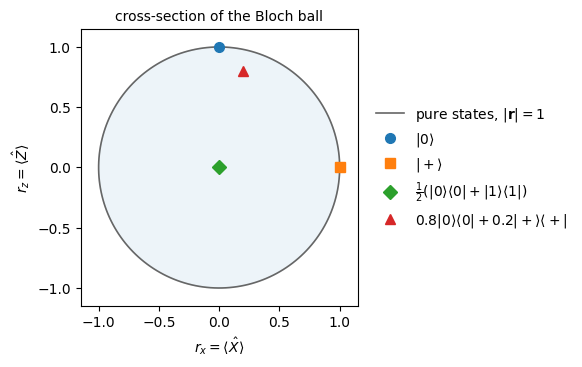

In [4]:
def bloch(rho):
    return jnp.real(jnp.array([jnp.trace(rho @ P) for P in (X, Y, Z)]))

def purity(rho):
    return float(jnp.real(jnp.trace(rho @ rho)))

def check_density_matrix(rho):
    ev = jnp.linalg.eigvalsh(rho)
    assert jnp.allclose(rho, rho.conj().T), "not Hermitian"
    assert abs(jnp.trace(rho) - 1) < TOL, "trace is not one"
    assert ev.min() > -TOL, "not positive"
    return ev

examples = {"|0>": dm(ket0), "|+>": rho_plus, "mixture": rho_mix,
            "0.8|0><0| + 0.2|+><+|": 0.8 * dm(ket0) + 0.2 * rho_plus}
print("state                      Bloch vector             |r|    purity   (1+|r|^2)/2")
for name, rho in examples.items():
    check_density_matrix(rho)
    r = bloch(rho); nr = float(jnp.linalg.norm(r))
    assert abs(purity(rho) - 0.5 * (1 + nr ** 2)) < TOL
    assert jnp.allclose(rho, 0.5 * (I2 + r[0] * X + r[1] * Y + r[2] * Z))
    print(f"{name:25s}  {np.round(np.asarray(r), 3)!s:22s}  {nr:.3f}   {purity(rho):.3f}    {0.5 * (1 + nr ** 2):.3f}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
phi = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(phi), np.sin(phi), color="0.4", lw=1.2, label="pure states, $|\\mathbf{r}|=1$")
ax.fill(np.cos(phi), np.sin(phi), color="C0", alpha=0.08)
for name, rho, m in [("$|0\\rangle$", dm(ket0), "o"), ("$|+\\rangle$", rho_plus, "s"), ("$\\frac{1}{2}(|0\\rangle\\langle0|+|1\\rangle\\langle1|)$", rho_mix, "D"),
                     ("$0.8|0\\rangle\\langle0|+0.2|+\\rangle\\langle+|$", examples["0.8|0><0| + 0.2|+><+|"], "^")]:
    r = np.asarray(bloch(rho)); ax.plot(r[0], r[2], m, ms=7, label=name)
ax.set_aspect("equal"); ax.set_xlabel("$r_x=\\langle\\hat X\\rangle$"); ax.set_ylabel("$r_z=\\langle\\hat Z\\rangle$")
ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10)
ax.set_title("cross-section of the Bloch ball")
save(fig, "fig_lab066_bloch_ball"); plt.show()
NUMBERS["PurityMixture"] = f"{purity(rho_mix):.1f}"


Pure states lie on the circle and mixtures inside it. The 50/50 mixture of $|0\rangle$ and $|1\rangle$ sits at the centre, with no preferred direction and purity $1/2$. The mixture of $|0\rangle$ and $|+\rangle$ lies on the straight line between the two pure states, because a mixture averages Bloch vectors with its weights.

## 4. The classical correlated coin as a density matrix

The Bell state and a classical source that emits $|00\rangle$ or $|11\rangle$ with probability one half each both give perfectly correlated bits in the $\hat Z$ basis. Their density matrices in the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$ are
$$\hat\rho_{\rm Bell}=|\Phi^+\rangle\langle\Phi^+|=\tfrac12\begin{pmatrix}1&0&0&1\\0&0&0&0\\0&0&0&0\\1&0&0&1\end{pmatrix},\qquad \hat\rho_{\rm coin}=\tfrac12\begin{pmatrix}1&0&0&0\\0&0&0&0\\0&0&0&0\\0&0&0&1\end{pmatrix}. \tag{5}$$
They differ only in the coherences between $|00\rangle$ and $|11\rangle$. With $\langle \hat O\rangle=\mathrm{Tr}(\hat O\hat\rho)$ we compute the three correlators and the purity of the register.

In [5]:
rho_bell = dm(phi_plus)
rho_coin = 0.5 * dm(kron_all(ket0, ket0)) + 0.5 * dm(kron_all(ket1, ket1))
def expval(rho, O):
    return float(jnp.real(jnp.trace(O @ rho)))
ZZ, XX, YY = jnp.kron(Z, Z), jnp.kron(X, X), jnp.kron(Y, Y)
print("register        <ZZ>    <XX>    <YY>    purity")
for name, rho in [("Bell", rho_bell), ("classical coin", rho_coin)]:
    check_density_matrix(rho)
    print(f"{name:14s}  {expval(rho, ZZ):+.2f}   {expval(rho, XX):+.2f}   {expval(rho, YY):+.2f}    {purity(rho):.2f}")
assert abs(expval(rho_bell, XX) - 1) < TOL and abs(expval(rho_coin, XX)) < TOL
assert abs(expval(rho_bell, YY) + 1) < TOL

register        <ZZ>    <XX>    <YY>    purity
Bell            +1.00   +1.00   -1.00    1.00
classical coin  +1.00   +0.00   +0.00    0.50


The coin matches $\langle \hat Z\hat Z\rangle=1$ and gives $\langle \hat X\hat X\rangle=\langle \hat Y\hat Y\rangle=0$, whereas the Bell state is correlated in all three bases. The register of the Bell state is pure, and the coin has purity $1/2$.

## 5. The partial trace of the register

We write the register state with one index for each qubit, $|\psi\rangle=\sum_{a,b}\psi_{ab}|a\rangle|b\rangle$. Here $a$ is the bit of qubit 0, $b$ the bit of qubit 1, and $\psi_{ab}$ the amplitude of the bit string $ab$. An observable that acts on qubit 0 alone has the form $\hat O_0\otimes \hat I$. In its expectation value the bra $\langle\psi|$ carries its own indices, written with primes, $a'$ and $b'$,
$$\langle\psi|\hat O_0\otimes \hat I|\psi\rangle=\sum_{a,a',b,b'}\psi^*_{a'b'}\,(\hat O_0)_{a'a}\,\delta_{b'b}\,\psi_{ab}=\sum_{a,a'}(\hat O_0)_{a'a}\underbrace{\sum_b\psi_{ab}\psi^*_{a'b}}_{(\hat\rho_0)_{aa'}}=\mathrm{Tr}(\hat O_0\hat\rho_0). \tag{6}$$
The identity on qubit 1 produces the Kronecker delta $\delta_{b'b}$, which sets the index of qubit 1 in $\psi$ and in $\psi^*$ equal, and that index is summed. The result depends on the state only through the $2\times2$ matrix
$$(\hat\rho_0)_{aa'}=\sum_b\psi_{ab}\,\psi^*_{a'b}, \tag{7}$$
the reduced density matrix of qubit 0. It contains everything that measurements on qubit 0 alone can reveal and is obtained by the partial trace over qubit 1, $\hat\rho_0=\mathrm{Tr}_1|\psi\rangle\langle\psi|$. In the same way the reduced state of qubit 1 is $(\hat\rho_1)_{bb'}=\sum_a\psi_{ab}\psi^*_{ab'}$, the partial trace over qubit 0. Written element by element for two qubits,
$$\hat\rho_0=\begin{pmatrix}|\psi_{00}|^2+|\psi_{01}|^2 & \psi_{00}\psi_{10}^*+\psi_{01}\psi_{11}^*\\ \psi_{10}\psi_{00}^*+\psi_{11}\psi_{01}^* & |\psi_{10}|^2+|\psi_{11}|^2\end{pmatrix}. \tag{8}$$
The diagonal holds the marginals of qubit 0, the probabilities of finding it in 0 or in 1 summed over both outcomes of qubit 1. Each off-diagonal element pairs amplitudes that agree on qubit 1.

### Three equivalent forms

The first form is the sum (7), written as explicit loops over $a$, $a'$ and $b$. The second form uses matrix language. The four amplitudes form the $2\times2$ amplitude matrix $\Psi_{ab}=\psi_{ab}$, with rows labelled by qubit 0 and columns by qubit 1, and the sum (7) becomes the matrix product
$$\hat\rho_0=\Psi\Psi^\dagger,\qquad \hat\rho_1=(\Psi^\dagger\Psi)^{T}. \tag{9}$$
In the $4\times4$ density matrix $\hat\rho=|\psi\rangle\langle\psi|$ with rows and columns $2a+b$, the element $(\hat\rho_0)_{aa'}$ is the trace of the $2\times2$ block in block-row $a$ and block-column $a'$.

The third form is a tensor contraction. The state tensor $\psi[a,b]$ and its conjugate are contracted over the index of qubit 1 while both indices of qubit 0 stay open. Einsum strings use single letters, so in the code an upper-case letter stands for a primed index, `A` for $a'$ and `B` for $b'$. With the operands `(psi, psi.conj())` the partial trace over qubit 1 is `"ab,Ab->aA"`, and over qubit 0 it is `"ab,aB->bB"`. The same contraction applied to the density tensor $\hat\rho[a,b,a',b']$, the $4\times4$ matrix reshaped to the shape $(2,2,2,2)$, reads `"abAb->aA"`, with a repeated index within one operand.

In the tensor-network diagrams of these contractions each tensor is a box and each index a leg. A leg joining two boxes, or two legs of one box, is a summed index. A loop over bit strings that uses only the flat index $2a+b$ of the $4\times4$ matrix serves as an independent reference, and all five computations must agree on any state.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


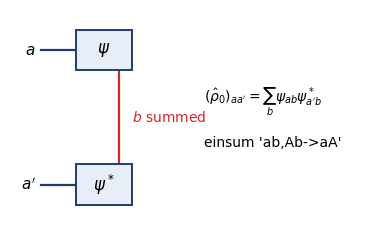

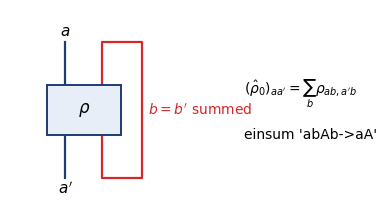

In [6]:
def box(ax, x, y, label, w=0.9, h=0.6):
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, fc="#e8eef7", ec="#1f3b70", lw=1.4, zorder=3))
    ax.text(x, y, label, ha="center", va="center", fontsize=12, zorder=4)

def leg(ax, xs, ys, label=None, lx=0, ly=0, color="#1f3b70"):
    ax.plot(xs, ys, color=color, lw=1.6, zorder=2)
    if label: ax.text(xs[-1] + lx, ys[-1] + ly, label, ha="center", va="center", fontsize=11)

fig, ax = plt.subplots(figsize=(4.6, 2.8))
box(ax, 0, 1, "$\\psi$"); box(ax, 0, -1, "$\\psi^*$")
leg(ax, [-0.45, -1.0], [1, 1], "$a$", lx=-0.18)              # open leg of qubit 0 on psi
leg(ax, [-0.45, -1.0], [-1, -1], "$a'$", lx=-0.2)            # open leg of qubit 0 on psi*
leg(ax, [0.25, 0.25], [0.7, -0.7], color="C3")                # joined leg of qubit 1: summed
ax.text(0.45, 0, "$b$ summed", color="C3", fontsize=10, va="center")
ax.text(1.6, 0, "$(\\hat\\rho_0)_{aa'}=\\sum_b\\psi_{ab}\\psi^*_{a'b}$\n\neinsum 'ab,Ab->aA'", fontsize=10, va="center")
ax.set_xlim(-1.5, 4.2); ax.set_ylim(-1.6, 1.6); ax.axis("off")
save(fig, "fig_lab066_tn_partial_trace"); plt.show()

fig, ax = plt.subplots(figsize=(4.6, 2.6))
box(ax, 0, 0, "$\\rho$", w=1.2, h=0.7)
leg(ax, [-0.3, -0.3], [0.35, 0.95], "$a$", ly=0.15); leg(ax, [-0.3, -0.3], [-0.35, -0.95], "$a'$", ly=-0.15)
ax.plot([0.3, 0.3, 0.95, 0.95, 0.3, 0.3], [0.35, 0.95, 0.95, -0.95, -0.95, -0.35], color="C3", lw=1.6, zorder=2)
ax.text(1.05, 0, "$b=b'$ summed", color="C3", fontsize=10, va="center")
ax.text(2.6, 0, "$(\\hat\\rho_0)_{aa'}=\\sum_b\\rho_{ab,a'b}$\n\neinsum 'abAb->aA'", fontsize=10, va="center")
ax.set_xlim(-1.2, 4.6); ax.set_ylim(-1.4, 1.4); ax.axis("off")
save(fig, "fig_lab066_tn_density_trace"); plt.show()

In the first diagram the upper box is the state tensor $\psi$ and the lower box its conjugate. The legs of qubit 0, drawn to the left, stay open and become the two indices of $\hat\rho_0$. The joined legs of qubit 1 form the sum over $b$. In the second diagram the density tensor carries all four legs, ket legs up and bra legs down. The trace over qubit 1 joins its ket leg $b$ to its bra leg $b'$.

In [7]:
def ptrace_sum(psi):
    # form 1: (rho_0)_{a a'} = sum_b psi_{ab} psi*_{a'b}, explicit loops (A stands for a')
    p = np.asarray(psi).reshape(2, 2)
    rho = np.zeros((2, 2), dtype=complex)
    for a in range(2):
        for A in range(2):
            for b in range(2):
                rho[a, A] += p[a, b] * np.conj(p[A, b])
    return jnp.asarray(rho)

def ptrace_matrix(psi, keep):
    # form 2: rho_0 = Psi Psi^dagger, rho_1 = (Psi^dagger Psi)^T
    Mmat = psi.reshape(2, 2)
    return Mmat @ Mmat.conj().T if keep == 0 else (Mmat.conj().T @ Mmat).T

def ptrace_blocks(rho4):
    # form 2': (rho_0)_{aA} = trace of the 2x2 block (a, A) of the 4x4 density matrix
    return jnp.array([[jnp.trace(rho4[2 * a:2 * a + 2, 2 * A:2 * A + 2]) for A in range(2)] for a in range(2)])

def ptrace_einsum(psi, keep):
    # form 3: tensor contraction of psi with psi*
    t = psi.reshape(2, 2)
    return jnp.einsum("ab,Ab->aA", t, t.conj()) if keep == 0 else jnp.einsum("ab,aB->bB", t, t.conj())

def ptrace_density_tensor(rho4, keep):
    # form 3': the density tensor rho[a,b,A,B] with a repeated index
    r = rho4.reshape(2, 2, 2, 2)
    return jnp.einsum("abAb->aA", r) if keep == 0 else jnp.einsum("abaB->bB", r)

def ptrace_loop(psi, keep, N):
    # independent reference: loop over all bit strings of the full projector, flat-index formula only
    rho = np.outer(np.asarray(psi), np.conj(np.asarray(psi)))
    rest = [q for q in range(N) if q not in keep]
    k = len(keep); out = np.zeros((2 ** k, 2 ** k), dtype=complex)
    for ka in itertools.product((0, 1), repeat=k):
        for kA in itertools.product((0, 1), repeat=k):
            for rb in itertools.product((0, 1), repeat=len(rest)):
                bits_row = [0] * N; bits_col = [0] * N
                for q, s in zip(keep, ka): bits_row[q] = s
                for q, s in zip(keep, kA): bits_col[q] = s
                for q, s in zip(rest, rb): bits_row[q] = s; bits_col[q] = s
                out[index_of(ka) if k else 0, index_of(kA) if k else 0] += rho[index_of(bits_row), index_of(bits_col)]
    return jnp.asarray(out)

key, sub = jax.random.split(key)
v = jax.random.normal(sub, (4,)) + 1j * jax.random.normal(jax.random.split(sub)[0], (4,))
psi_rand = v / jnp.linalg.norm(v)
rho4 = dm(psi_rand)
rA = ptrace_einsum(psi_rand, 0)
for other in (ptrace_sum(psi_rand), ptrace_matrix(psi_rand, 0), ptrace_blocks(rho4),
              ptrace_density_tensor(rho4, 0), ptrace_loop(psi_rand, [0], 2)):
    assert jnp.allclose(rA, other, atol=TOL)
rB = ptrace_einsum(psi_rand, 1)
for other in (ptrace_matrix(psi_rand, 1), ptrace_density_tensor(rho4, 1), ptrace_loop(psi_rand, [1], 2)):
    assert jnp.allclose(rB, other, atol=TOL)
check_density_matrix(rA); check_density_matrix(rB)
print("random register state, amplitudes:", np.round(np.asarray(psi_rand), 3))
print("rho_0 from all five methods agrees:\n", np.round(np.asarray(rA), 4))
print("rho_1 from all four methods agrees:\n", np.round(np.asarray(rB), 4))

random register state, amplitudes: [ 0.355+0.01j  -0.159-0.076j  0.611-0.616j  0.3  +0.025j]
rho_0 from all five methods agrees:
 [[0.1571+0.j     0.161 +0.2058j]
 [0.161 -0.2058j 0.8429+0.j    ]]
rho_1 from all four methods agrees:
 [[0.8784+0.j     0.1103-0.1745j]
 [0.1103+0.1745j 0.1216+0.j    ]]


All the methods give the same reduced matrices, which are Hermitian, of trace one and positive. The einsum form never builds the $2^N\times2^N$ matrix and scales to larger registers.

### Three examples

We apply equation (7) to three register states and compare with the code. The product state $(\cos\alpha|0\rangle+\sin\alpha|1\rangle)\otimes|1\rangle$ has the amplitudes $\psi_{01}=\cos\alpha$ and $\psi_{11}=\sin\alpha$, all others zero. Only $b=1$ contributes, and
$$\hat\rho_0=\begin{pmatrix}\cos^2\alpha&\cos\alpha\sin\alpha\\ \cos\alpha\sin\alpha&\sin^2\alpha\end{pmatrix}, \tag{10}$$
the pure state of qubit 0 itself, so a product state leaves each qubit in its own pure state.

The Bell state has $\psi_{00}=\psi_{11}=1/\sqrt2$, so $\Psi=I/\sqrt2$ and $\hat\rho_0=\Psi\Psi^\dagger=I/2$. The register is in a fully known pure state, yet each qubit alone is a fair coin in every basis. The local state $\hat I/2$ fixes every prediction for measurements on one qubit. The perfect correlations of the Bell state appear only in joint measurements of both qubits. A pure register whose single qubits are mixed is entangled, and here the parts are even maximally mixed.

The family $\cos\theta|00\rangle+\sin\theta|11\rangle$ has $\Psi=\mathrm{diag}(\cos\theta,\sin\theta)$ and $\hat\rho_0=\mathrm{diag}(\cos^2\theta,\sin^2\theta)$. It interpolates between the product state $|00\rangle$ at $\theta=0$ and the Bell state at $\theta=\pi/4$.

In [8]:
alpha, theta = np.pi / 6, np.pi / 8
psi_prod = kron_all(jnp.cos(alpha) * ket0 + jnp.sin(alpha) * ket1, ket1)
psi_theta = jnp.array([np.cos(theta), 0, 0, np.sin(theta)], dtype=jnp.complex128)
cases = {"product": psi_prod, "Bell": phi_plus, "theta = pi/8": psi_theta}
hand = {"product": jnp.array([[np.cos(alpha) ** 2, np.cos(alpha) * np.sin(alpha)], [np.cos(alpha) * np.sin(alpha), np.sin(alpha) ** 2]]),
        "Bell": jnp.eye(2) / 2,
        "theta = pi/8": jnp.diag(jnp.array([np.cos(theta) ** 2, np.sin(theta) ** 2]))}
for name, psi in cases.items():
    rA = ptrace_einsum(psi, 0)
    assert jnp.allclose(rA, hand[name], atol=TOL)
    print(f"{name:13s} rho_0 =", np.round(np.asarray(rA).real, 4).tolist())

product       rho_0 = [[0.75, 0.433], [0.433, 0.25]]
Bell          rho_0 = [[0.5, 0.0], [0.0, 0.5]]
theta = pi/8  rho_0 = [[0.8536, 0.0], [0.0, 0.1464]]


### More qubits

The same rule holds for any number of qubits. For three qubits, the state tensor $\psi[a,b,c]$ is contracted with $\psi^*$ over the indices of the traced qubits. Keeping qubit 0 is `"abc,Abc->aA"`, keeping qubit 1 is `"abc,aBc->bB"`, and keeping qubits 0 and 2 is `"abc,AbC->acAC"`. The four open indices of the last string are regrouped into a $4\times4$ matrix by a reshape, with the first kept qubit as the most significant bit. We check these strings on a random three-qubit state against the loop reference.

In [9]:
key, sub = jax.random.split(key)
k1, k2 = jax.random.split(sub)
v3 = jax.random.normal(k1, (8,)) + 1j * jax.random.normal(k2, (8,))
psi3 = v3 / jnp.linalg.norm(v3)
t3 = psi3.reshape(2, 2, 2)
r0 = jnp.einsum("abc,Abc->aA", t3, t3.conj())
r1 = jnp.einsum("abc,aBc->bB", t3, t3.conj())
r02 = jnp.einsum("abc,AbC->acAC", t3, t3.conj()).reshape(4, 4)
assert jnp.allclose(r0, ptrace_loop(psi3, [0], 3), atol=TOL)
assert jnp.allclose(r1, ptrace_loop(psi3, [1], 3), atol=TOL)
assert jnp.allclose(r02, ptrace_loop(psi3, [0, 2], 3), atol=TOL)
check_density_matrix(r02)
print("three-qubit partial traces agree with the loop reference; rho_02 has trace", round(float(jnp.real(jnp.trace(r02))), 12))

three-qubit partial traces agree with the loop reference; rho_02 has trace 1.0


## 6. Purity of the reduced state

The purity $\mathrm{Tr}\hat\rho_0^2$ measures how mixed qubit 0 is on its own. It equals $1$ for the product state and $\mathrm{Tr}(\hat I/4)=1/2$ for the Bell state. For the family it equals $\cos^4\theta+\sin^4\theta$, which falls from 1 at $\theta=0$ to $1/2$ at $\theta=\pi/4$. The register itself is pure in all three cases, so a reduced purity below one comes entirely from the correlations between the qubits.

In [10]:
for name, psi in cases.items():
    print(f"{name:13s} purity of rho_0 = {purity(ptrace_einsum(psi, 0)):.4f}")
thetas = np.linspace(0, np.pi / 2, 181)
pur_theta = np.array([purity(ptrace_einsum(jnp.array([np.cos(t), 0, 0, np.sin(t)], dtype=jnp.complex128), 0)) for t in thetas])
assert np.allclose(pur_theta, np.cos(thetas) ** 4 + np.sin(thetas) ** 4)
assert abs(purity(ptrace_einsum(phi_plus, 0)) - 0.5) < TOL
NUMBERS["PurityThetaPiEight"] = f"{np.cos(theta) ** 4 + np.sin(theta) ** 4:.2f}"


product       purity of rho_0 = 1.0000
Bell          purity of rho_0 = 0.5000
theta = pi/8  purity of rho_0 = 0.7500


## 7. Entanglement entropy

The eigenvalues $\lambda_k$ of $\hat\rho_0$ are probabilities, and their Shannon entropy in bits is the von Neumann entropy
$$S(\hat\rho_0)=-\mathrm{Tr}\,\hat\rho_0\log_2\hat\rho_0=-\sum_k\lambda_k\log_2\lambda_k , \tag{11}$$
with $0\log0=0$. For a pure register it is called the entanglement entropy. It is zero for a product state, one bit for the Bell state, and for the family it is the binary entropy $S_{\rm bin}(\cos^2\theta)$ with $S_{\rm bin}(p)=-p\log_2p-(1-p)\log_2(1-p)$.

The entropy follows without forming $\hat\rho_0$. The singular value decomposition of the amplitude matrix, $\Psi=U\,\mathrm{diag}(s_k)\,V^\dagger$, gives $\hat\rho_0=\Psi\Psi^\dagger=U\,\mathrm{diag}(s_k^2)\,U^\dagger$. The eigenvalues of $\hat\rho_0$ are the squared singular values, the squared Schmidt coefficients, so $\lambda_k=s_k^2$. Since $\Psi^\dagger\Psi$ has the same nonzero eigenvalues, the two qubits of a pure register always have equal entropies, $S(\hat\rho_0)=S(\hat\rho_1)$. We compute $S$ along the family, compare it with $S_{\rm bin}(\cos^2\theta)$ and with the singular values, and check $S(\hat\rho_0)=S(\hat\rho_1)$ for a random state.

product       S(rho_0) = 0.0000 bits, from singular values 0.0000
Bell          S(rho_0) = 1.0000 bits, from singular values 1.0000
theta = pi/8  S(rho_0) = 0.6009 bits, from singular values 0.6009
random state  S(rho_0) = 0.3618, S(rho_1) = 0.3618


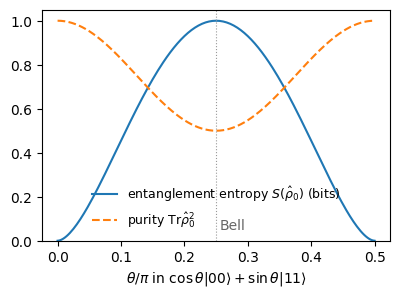

In [11]:
def entropy_bits(rho):
    ev = np.clip(np.asarray(jnp.linalg.eigvalsh(rho)), 0, None)
    ev = ev[ev > 1e-15]
    return abs(float(-np.sum(ev * np.log2(ev))))

def entropy_from_svd(psi):
    mu2 = np.asarray(jnp.linalg.svd(psi.reshape(2, 2), compute_uv=False)) ** 2
    mu2 = mu2[mu2 > 1e-15]
    return abs(float(-np.sum(mu2 * np.log2(mu2))))

def h2(p):
    p = np.clip(p, 1e-300, 1)
    q = np.clip(1 - p, 1e-300, 1)
    return -p * np.log2(p) - q * np.log2(q)

S_theta = np.array([entropy_bits(ptrace_einsum(jnp.array([np.cos(t), 0, 0, np.sin(t)], dtype=jnp.complex128), 0)) for t in thetas])
S_svd = np.array([entropy_from_svd(jnp.array([np.cos(t), 0, 0, np.sin(t)], dtype=jnp.complex128)) for t in thetas])
assert np.allclose(S_theta, h2(np.cos(thetas) ** 2), atol=1e-9) and np.allclose(S_theta, S_svd, atol=1e-9)
assert abs(entropy_bits(ptrace_einsum(psi_rand, 0)) - entropy_bits(ptrace_einsum(psi_rand, 1))) < 1e-10
for name, psi in cases.items():
    print(f"{name:13s} S(rho_0) = {entropy_bits(ptrace_einsum(psi, 0)):.4f} bits, from singular values {entropy_from_svd(psi):.4f}")
print(f"random state  S(rho_0) = {entropy_bits(ptrace_einsum(psi_rand, 0)):.4f}, S(rho_1) = {entropy_bits(ptrace_einsum(psi_rand, 1)):.4f}")

fig, ax = plt.subplots(figsize=(4.5, 3.0))
ax.plot(thetas / np.pi, S_theta, label="entanglement entropy $S(\\hat\\rho_0)$ (bits)")
ax.plot(thetas / np.pi, pur_theta, ls="--", label="purity Tr$\\hat\\rho_0^2$")
ax.axvline(0.25, color="0.6", lw=0.8, ls=":")
ax.set_xlabel("$\\theta/\\pi$ in $\\cos\\theta|00\\rangle+\\sin\\theta|11\\rangle$"); ax.set_ylim(0, 1.05)
ax.text(0.255, 0.05, "Bell", color="0.4"); ax.legend(loc="lower center", frameon=False)
save(fig, "fig_lab066_entropy_theta"); plt.show()
NUMBERS["EntropyThetaPiEight"] = f"{entropy_bits(ptrace_einsum(psi_theta, 0)):.2f}"
NUMBERS["EntropyRandom"] = f"{entropy_bits(ptrace_einsum(psi_rand, 0)):.2f}"


The entropy rises from zero for the product state $|00\rangle$ to one bit at the Bell state, $\theta=\pi/4$, and returns to zero at $|11\rangle$. The purity falls from one to one half and back. Both curves depend only on the eigenvalues $\cos^2\theta$ and $\sin^2\theta$ of $\hat\rho_0$.

The entropy of a reduced state measures entanglement only when the whole register is pure. The classical correlated coin is a mixed register, and its qubit 0 is also a fair coin, $\hat\rho_0=\hat I/2$, with one bit of entropy. That bit is ordinary ignorance about which of $|00\rangle$ and $|11\rangle$ was emitted, and the coin contains no entanglement. The code shows that one qubit alone cannot distinguish the two registers.

In [12]:
def ptrace_dm(rho4, keep):
    return ptrace_density_tensor(rho4, keep)
for name, rho in [("Bell", rho_bell), ("classical coin", rho_coin)]:
    rA = ptrace_dm(rho, 0)
    print(f"{name:14s} rho_0 = {np.round(np.asarray(rA).real, 3).tolist()}, S(rho_0) = {entropy_bits(rA):.2f} bit, purity of the register = {purity(rho):.2f}")
assert jnp.allclose(ptrace_dm(rho_bell, 0), ptrace_dm(rho_coin, 0))

Bell           rho_0 = [[0.5, 0.0], [0.0, 0.5]], S(rho_0) = 1.00 bit, purity of the register = 1.00
classical coin rho_0 = [[0.5, 0.0], [0.0, 0.5]], S(rho_0) = 1.00 bit, purity of the register = 0.50


In both registers qubit 0 is the same fair coin, and only the joint correlations and the purity of the register, computed in Section 4, distinguish them.

### Rank, purity and entropy of pure and mixed states

A pure state has a density matrix of rank one with $\hat\rho^2=\hat\rho$, purity one and zero entropy. A mixture $\hat\rho=\sum_ip_i|\psi_i\rangle\langle\psi_i|$ of two or more different states has rank at least two, so at least two of its eigenvalues $\lambda_k$ are nonzero. The purity $\mathrm{Tr}\hat\rho^2=\sum_k\lambda_k^2$ is then smaller than one and the entropy (11) larger than zero. For a register of dimension $d$ the extreme case is $\hat I/d$, with rank $d$, purity $1/d$ and entropy $\log_2d$ bits. The code lists rank, purity and entropy for five density matrices of the register and of one qubit.

In [13]:
psi_prod_reg = kron_all(ket0, (ket0 + ket1) / jnp.sqrt(2.0))        # |0>|+>, a pure product register
rho_prod_reg = dm(psi_prod_reg)
assert jnp.allclose(rho_prod_reg @ rho_prod_reg, rho_prod_reg, atol=TOL)   # pure: rho^2 = rho
assert jnp.allclose(rho_bell @ rho_bell, rho_bell, atol=TOL)
table = [("pure product register |0>|+>", rho_prod_reg),
         ("Bell register |Phi+><Phi+|", rho_bell),
         ("qubit 0 of the Bell register", ptrace_dm(rho_bell, 0)),
         ("classical correlated coin", rho_coin),
         ("maximally mixed register I/4", jnp.eye(4, dtype=jnp.complex128) / 4)]
print(f"{'density matrix':32s} {'dim':>3s} {'rank':>4s} {'purity':>7s} {'S (bits)':>8s}")
pm = {}
for name, rho in table:
    check_density_matrix(rho)
    pm[name] = (rho.shape[0], rank(rho), purity(rho), entropy_bits(rho))
    print(f"{name:32s} {pm[name][0]:3d} {pm[name][1]:4d} {pm[name][2]:7.3f} {pm[name][3]:8.3f}")
assert [v[1] for v in pm.values()] == [1, 1, 2, 2, 4]
assert np.allclose([v[2] for v in pm.values()], [1, 1, 0.5, 0.5, 0.25])
assert np.allclose([v[3] for v in pm.values()], [0, 0, 1, 1, 2], atol=1e-9)
NUMBERS["RankCoin"] = str(pm["classical correlated coin"][1])
NUMBERS["PurityIFour"] = f"{pm['maximally mixed register I/4'][2]:.2f}"
NUMBERS["EntropyIFour"] = f"{pm['maximally mixed register I/4'][3]:.0f}"


density matrix                   dim rank  purity S (bits)
pure product register |0>|+>       4    1   1.000    0.000
Bell register |Phi+><Phi+|         4    1   1.000    0.000
qubit 0 of the Bell register       2    2   0.500    1.000
classical correlated coin          4    2   0.500    1.000
maximally mixed register I/4       4    4   0.250    2.000


Both pure registers, the product state and the entangled one, have rank one, purity one and zero entropy. The entanglement of a pure register shows only in its parts, and qubit 0 of the Bell register has rank two, purity $1/2$ and one bit of entropy. The classical coin has the same rank, purity and entropy as that reduced state, but its mixedness belongs to the whole register and expresses ignorance about the source. For a pure register any mixedness of a part comes from correlations with the rest, whereas for a mixed register it can also be classical uncertainty.

## 8. Measurement and its back-action

A projective measurement is described by projectors $\hat P_k$ with $\hat P_k\hat P_l=\delta_{kl}\hat P_k$ and $\sum_k\hat P_k=\hat I$, one for each outcome $k$. The Born rule gives the probability $p_k=\mathrm{Tr}(\hat P_k\hat\rho)$, and after the outcome $k$ the state is updated by the Lüders rule,
$$\hat\rho\;\longrightarrow\;\hat\rho_k=\frac{\hat P_k\,\hat\rho\,\hat P_k}{p_k}. \tag{12}$$
Measuring qubit 0 in the $\hat Z$ basis uses $\hat P_0=|0\rangle\langle0|\otimes \hat I$ and $\hat P_1=|1\rangle\langle1|\otimes \hat I$. In the $\hat X$ basis the projectors are $|\pm\rangle\langle\pm|\otimes \hat I$, with the outcome bit 0 for $+$.

The measurement acts on one qubit, and in an entangled register it changes the other one too. For the Bell state, the outcome 0 in $\hat Z$ on qubit 0 leaves qubit 1 in $|0\rangle$, and the outcome $+$ in $\hat X$ leaves it in $|+\rangle$. The partner qubit, a fair coin before, is now in a definite pure state correlated with the observed outcome in the chosen basis. We compute the post-measurement reduced state of qubit 1. We then simulate records in which qubit 0 is measured first and qubit 1 afterwards in the same basis, each outcome sampled from the updated state. The classical correlated coin serves as the comparison, and the $\hat Y$ basis is included because $\langle \hat Y\hat Y\rangle=-1$ for the Bell state.

In [14]:
def projectors(basis):
    if basis == "Z": vecs = (ket0, ket1)
    elif basis == "X": vecs = ((ket0 + ket1) / jnp.sqrt(2.0), (ket0 - ket1) / jnp.sqrt(2.0))
    else: vecs = ((ket0 + 1j * ket1) / jnp.sqrt(2.0), (ket0 - 1j * ket1) / jnp.sqrt(2.0))
    return [dm(v) for v in vecs]

def measure(rho, q, basis, outcome):
    # projective measurement of qubit q of a two-qubit register; returns probability and post-measurement state
    P1 = projectors(basis)[outcome]
    P = jnp.kron(P1, I2) if q == 0 else jnp.kron(I2, P1)
    p = float(jnp.real(jnp.trace(P @ rho)))
    return p, (P @ rho @ P) / p

for basis in ["Z", "X"]:
    for outcome in (0, 1):
        p, post = measure(rho_bell, 0, basis, outcome)
        r1 = ptrace_dm(post, 1)
        target = projectors(basis)[outcome]
        assert jnp.allclose(r1, target, atol=TOL) and abs(p - 0.5) < TOL
        print(f"basis {basis}, outcome {outcome} on qubit 0 (p = {p:.2f}): qubit 1 now has Bloch vector {np.round(np.asarray(bloch(r1)), 3)}")

def sequential_record(key, rho, basis, shots):
    agree = 0
    for _ in range(shots):
        key, k0, k1 = jax.random.split(key, 3)
        p0 = measure(rho, 0, basis, 0)[0]
        o0 = int(jax.random.uniform(k0) > p0)
        _, post = measure(rho, 0, basis, o0)
        p1 = float(jnp.real(jnp.trace(projectors(basis)[0] @ ptrace_dm(post, 1))))
        o1 = int(jax.random.uniform(k1) > p1)
        agree += (o0 == o1)
    return agree / shots

REC = 200
agreement = {}
print(f"fraction of {REC} shots in which qubit 1 repeats the outcome of qubit 0")
print("register          Z      X      Y")
for name, rho in [("Bell", rho_bell), ("classical coin", rho_coin)]:
    row = []
    for basis in ["Z", "X", "Y"]:
        key, sub = jax.random.split(key)                     # a separate key for every basis and register
        row.append(sequential_record(sub, rho, basis, REC))
    agreement[name] = row
    print(f"{name:15s} " + "  ".join(f"{f:.2f}" for f in row))
assert agreement["Bell"][0] == 1.0 and agreement["Bell"][1] == 1.0 and agreement["Bell"][2] == 0.0
assert agreement["classical coin"][0] == 1.0 and 0.35 < agreement["classical coin"][1] < 0.65
NUMBERS["CoinAgreementX"] = f"{agreement['classical coin'][1]:.2f}"
NUMBERS["RecShots"] = f"{REC}"
for name, word in (("Bell", "Bell"), ("classical coin", "Coin")):
    for k, basis in enumerate("ZXY"):
        if (word, basis) != ("Coin", "X"):                  # the coin in X keeps its earlier name CoinAgreementX
            NUMBERS[f"Agree{word}{basis}"] = f"{agreement[name][k]:.2f}"

# no signalling: averaged over the unread outcome of qubit 0, qubit 1 is unchanged
for basis in ["Z", "X", "Y"]:
    avg = sum(measure(rho_bell, 0, basis, o)[0] * measure(rho_bell, 0, basis, o)[1] for o in (0, 1))
    r1 = ptrace_dm(avg, 1)
    assert jnp.allclose(r1, I2 / 2, atol=TOL)
    print(f"after an unread {basis} measurement of qubit 0, rho_1 =", np.round(np.asarray(r1).real, 3).tolist())

basis Z, outcome 0 on qubit 0 (p = 0.50): qubit 1 now has Bloch vector [0. 0. 1.]
basis Z, outcome 1 on qubit 0 (p = 0.50): qubit 1 now has Bloch vector [ 0.  0. -1.]
basis X, outcome 0 on qubit 0 (p = 0.50): qubit 1 now has Bloch vector [1. 0. 0.]
basis X, outcome 1 on qubit 0 (p = 0.50): qubit 1 now has Bloch vector [-1.  0.  0.]
fraction of 200 shots in which qubit 1 repeats the outcome of qubit 0
register          Z      X      Y
Bell            1.00  1.00  0.00
classical coin  1.00  0.48  0.51
after an unread Z measurement of qubit 0, rho_1 = [[0.5, 0.0], [0.0, 0.5]]
after an unread X measurement of qubit 0, rho_1 = [[0.5, 0.0], [0.0, 0.5]]
after an unread Y measurement of qubit 0, rho_1 = [[0.5, 0.0], [0.0, 0.5]]


For the Bell state the partner qubit is left in a definite eigenstate of the same basis, fixed by the outcome on qubit 0. It is the same eigenstate in the $\hat Z$ and $\hat X$ bases and the opposite one in the $\hat Y$ basis. The records agree in every shot in $\hat Z$ and $\hat X$ and disagree in every shot in $\hat Y$, as $\langle \hat Y\hat Y\rangle=-1$ predicts. The classical coin agrees in $\hat Z$ only, and in $\hat X$ its two records agree in about half of the shots, like two independent coins. Before the measurement qubit 1 of the Bell state was a fair coin in every basis, so the measurement on qubit 0 has changed the predictions for qubit 1. The last lines of the output average the post-measurement states over the outcomes of qubit 0, which nobody at qubit 1 knows. Qubit 1 then remains $\hat I/2$ in every case, so the back-action transmits no signal.

## 9. Unread measurements and general measurements

If a measurement happens but its outcome is not recorded, the state is the average of the post-measurement states weighted with their probabilities,
$$\hat\rho\;\longrightarrow\;\sum_kp_k\hat\rho_k=\sum_k\hat P_k\,\hat\rho\,\hat P_k . \tag{13}$$
The average keeps the blocks of $\hat\rho$ within each outcome sector and removes the coherences between different outcome sectors. For projectors of rank one, as in a measurement of all qubits in a basis, it keeps the diagonal and removes every off-diagonal coherence. An unread $\hat Z$ measurement turns $|+\rangle$ into the 50/50 mixture, and an unread $\hat Z$ measurement of qubit 0 turns the Bell state into the classical correlated coin. Loss of coherence in a fixed basis is called dephasing, and an environment that records the value of the qubit has the same effect.

A general measurement, a positive operator-valued measure (POVM), is any set of positive matrices $\hat\pi_k$ with $\sum_k\hat\pi_k=\hat I$, with the Born rule $p_k=\mathrm{Tr}(\hat\pi_k\hat\rho)$. Projective measurements are the special case of projectors. A detector for the $\hat Z$ basis that reports the wrong bit with probability $\epsilon$ has $\hat\pi_0=(1-\epsilon)|0\rangle\langle0|+\epsilon|1\rangle\langle1|$ and $\hat\pi_1=\hat I-\hat\pi_0$. POVMs describe noisy readout and randomised measurements.

In [15]:
def unread(rho, q, basis):
    out = 0
    for P1 in projectors(basis):
        P = jnp.kron(P1, I2) if q == 0 else jnp.kron(I2, P1)
        out = out + P @ rho @ P
    return out

def unread_1q(rho, basis):
    return sum(P @ rho @ P for P in projectors(basis))

assert jnp.allclose(unread_1q(rho_plus, "Z"), rho_mix)
assert jnp.allclose(unread(rho_bell, 0, "Z"), rho_coin)
print(f"unread Z measurement of |+>: purity {purity(rho_plus):.2f} -> {purity(unread_1q(rho_plus, 'Z')):.2f}")
rb = unread(rho_bell, 0, "Z")
print(f"unread Z measurement of qubit 0 of the Bell state: <XX> {expval(rho_bell, XX):.2f} -> {expval(rb, XX):.2f}; <ZZ> {expval(rho_bell, ZZ):.2f} -> {expval(rb, ZZ):.2f}")

eps = 0.1
E0 = (1 - eps) * dm(ket0) + eps * dm(ket1); E1 = I2 - E0
assert jnp.allclose(E0 + E1, I2) and min(jnp.linalg.eigvalsh(E0).min(), jnp.linalg.eigvalsh(E1).min()) >= 0
for name, rho in [("|0>", dm(ket0)), ("|+>", rho_plus)]:
    print(f"noisy detector, eps = {eps}: state {name:4s} gives p(0) = {float(jnp.real(jnp.trace(E0 @ rho))):.2f}")

unread Z measurement of |+>: purity 1.00 -> 0.50
unread Z measurement of qubit 0 of the Bell state: <XX> 1.00 -> 0.00; <ZZ> 1.00 -> 1.00
noisy detector, eps = 0.1: state |0>  gives p(0) = 0.90
noisy detector, eps = 0.1: state |+>  gives p(0) = 0.50


### Measuring a Pauli string with an ancilla

A Pauli string such as $\hat Z_0\hat Z_1$ can be measured without measuring the two qubits separately. A third qubit, the ancilla, starts in $|0\rangle$. The gates $\widehat{\mathrm{CNOT}}_{0\to2}$ and $\widehat{\mathrm{CNOT}}_{1\to2}$ add both bits to it modulo 2, so the ancilla ends in $|b_0\oplus b_1\rangle$, and measuring it returns the parity of the register. The probability of the outcome 0 is $(1+\langle \hat Z_0\hat Z_1\rangle)/2$. Only the parity is recorded, so the register is projected onto the subspace of the observed parity with the projectors $\hat P_\pm=\tfrac12(\hat I\pm \hat Z_0\hat Z_1)$, and superpositions inside that subspace survive. The Bell state $|\Phi^+\rangle$ has even parity and is left unchanged, whereas a measurement of each qubit separately destroys it. Hadamard gates on both qubits before and after the CNOT gates turn the circuit into a measurement of $\hat X_0\hat X_1$, because $\hat H$ exchanges $\hat X$ and $\hat Z$.

### A symmetric informationally complete POVM

A POVM is informationally complete when its outcome probabilities determine every density matrix. Its elements must span the space of Hermitian matrices, so a qubit needs at least $d^2=4$ elements, and more are allowed. The minimal choice uses four Bloch vectors pointing to the corners of a regular tetrahedron,
$$\mathbf s_1=(0,0,1),\quad \mathbf s_2=\big(\tfrac{2\sqrt2}3,0,-\tfrac13\big),\quad \mathbf s_3=\big(-\tfrac{\sqrt2}3,\sqrt{\tfrac23},-\tfrac13\big),\quad \mathbf s_4=\big(-\tfrac{\sqrt2}3,-\sqrt{\tfrac23},-\tfrac13\big), \tag{14}$$
and the elements $\hat\pi_a=\tfrac14(\hat I+\mathbf s_a\cdot\hat{\boldsymbol\sigma})$, $a=1,\dots,4$. They are positive and sum to $\hat I$, because the four vectors add to zero. For a state with Bloch vector $\mathbf r$ the outcome probabilities are $p_a=\mathrm{Tr}(\hat\pi_a\hat\rho)=\tfrac14(1+\mathbf s_a\cdot\mathbf r)$. The four vectors satisfy $\sum_a\mathbf s_a\mathbf s_a^T=\tfrac43I$, so $\sum_ap_a\mathbf s_a=\mathbf r/3$, and the Bloch vector follows from the four probabilities,
$$\mathbf r=3\sum_{a=1}^4p_a\,\mathbf s_a . \tag{15}$$
Informationally complete measurements are the starting point of state tomography.

In [16]:
# (1) parity of the register read out through an ancilla (qubit 2)
def cnot3(c, t):
    # CNOT with control c and target t on three qubits, as a permutation of bit strings
    M_ = np.zeros((8, 8), dtype=complex)
    for i in range(8):
        j = i ^ (1 << (2 - t)) if (i >> (2 - c)) & 1 else i
        M_[j, i] = 1
    return jnp.asarray(M_)

def ancilla_parity(psi_reg, basis="Z"):
    # returns p(ancilla = 0) and the normalised register state after each outcome
    B = jnp.kron(H, H) if basis == "X" else jnp.eye(4, dtype=jnp.complex128)
    v = jnp.kron(B @ psi_reg, ket0)
    v = cnot3(1, 2) @ (cnot3(0, 2) @ v)
    t = v.reshape(4, 2)                                   # register index, ancilla bit
    out = {}
    for a in (0, 1):
        w = B.conj().T @ t[:, a]                          # undo the basis change on the register
        out[a] = (float(jnp.real(jnp.vdot(w, w))), w / jnp.linalg.norm(w) if jnp.linalg.norm(w) > 1e-12 else w)
    return out

kpa, kpb = jax.random.split(jax.random.PRNGKey(6609))      # own key for this check
v = jax.random.normal(kpa, (4,)) + 1j * jax.random.normal(kpb, (4,)); psi_par = v / jnp.linalg.norm(v)
for basis, PP in (("Z", ZZ), ("X", XX)):
    res = ancilla_parity(psi_par, basis)
    p0 = res[0][0]
    assert abs(p0 - (1 + expval(dm(psi_par), PP)) / 2) < 1e-12              # p(even) = (1 + <PP>)/2
    for a, sgn in ((0, 1), (1, -1)):
        Pproj = (jnp.eye(4) + sgn * PP) / 2
        target = Pproj @ psi_par; target = target / jnp.linalg.norm(target)
        assert abs(abs(jnp.vdot(target, res[a][1])) - 1) < 1e-12               # projected onto the parity subspace
res_bell = ancilla_parity(phi_plus, "Z")
assert abs(res_bell[0][0] - 1) < 1e-12 and abs(abs(jnp.vdot(phi_plus, res_bell[0][1])) - 1) < 1e-12
print(f"random state: p(even Z0Z1) = {ancilla_parity(psi_par, 'Z')[0][0]:.3f} = (1 + <Z0Z1>)/2; the register is projected onto the parity subspace")
print("Bell state: parity even with probability 1 and the state is unchanged")

# (2) tetrahedral SIC-POVM
s_vec = np.array([[0, 0, 1], [2 * np.sqrt(2) / 3, 0, -1 / 3], [-np.sqrt(2) / 3, np.sqrt(2 / 3), -1 / 3], [-np.sqrt(2) / 3, -np.sqrt(2 / 3), -1 / 3]])
sic = [(I2 + s[0] * X + s[1] * Y + s[2] * Z) / 4 for s in s_vec]
assert jnp.allclose(sum(sic), I2, atol=TOL) and all(float(jnp.linalg.eigvalsh(E).min()) > -TOL for E in sic)
assert np.allclose(s_vec.T @ s_vec, 4 / 3 * np.eye(3))
for name, rho in [("|0>", dm(ket0)), ("|+>", rho_plus), ("mixture", rho_mix), ("random", rho_test if "rho_test" in dir() else 0.5 * (I2 + 0.3 * X - 0.5 * Y + 0.2 * Z))]:
    p_sic = np.array([float(jnp.real(jnp.trace(E @ rho))) for E in sic])
    assert np.all(p_sic >= -TOL) and abs(p_sic.sum() - 1) < 1e-12
    assert np.allclose(3 * p_sic @ s_vec, np.asarray(bloch(rho)), atol=1e-12)        # r = 3 sum_a p_a s_a
    print(f"SIC probabilities for {name:8s}: {np.round(p_sic, 3)}  ->  Bloch vector {np.round(3 * p_sic @ s_vec, 3)}")


random state: p(even Z0Z1) = 0.896 = (1 + <Z0Z1>)/2; the register is projected onto the parity subspace
Bell state: parity even with probability 1 and the state is unchanged
SIC probabilities for |0>     : [0.5   0.167 0.167 0.167]  ->  Bloch vector [0. 0. 1.]
SIC probabilities for |+>     : [0.25  0.486 0.132 0.132]  ->  Bloch vector [ 1. -0. -0.]
SIC probabilities for mixture : [0.25 0.25 0.25 0.25]  ->  Bloch vector [0. 0. 0.]
SIC probabilities for random  : [0.3   0.304 0.096 0.3  ]  ->  Bloch vector [ 0.3 -0.5  0.2]


## 10. Noise as quantum channels

A qubit in a laboratory is never completely isolated. The smallest example of an environment is one further qubit $E$ that starts in $|0\rangle_E$ and that we never observe. The coupling Hamiltonian $\hat{\mathcal H}=\tfrac{\Omega}{2}\,|1\rangle\langle1|\otimes \hat Y$ rotates the environment qubit about $y$ only when the system qubit is $|1\rangle$. Switched on for a time $t$ it gives the controlled rotation
$$\hat U=e^{-i\hat{\mathcal H}t}=|0\rangle\langle0|\otimes \hat I+|1\rangle\langle1|\otimes \hat R_y(g),\qquad g=\Omega t , \tag{16}$$
and we take $0\le g\le\pi$. A system state $\alpha|0\rangle+\beta|1\rangle$ becomes
$$\alpha\,|0\rangle|0\rangle_E+\beta\,|1\rangle\big(\cos\tfrac g2|0\rangle_E+\sin\tfrac g2|1\rangle_E\big), \tag{17}$$
so the environment has partly recorded whether the system is in $|1\rangle$. We sort the terms by the final state of the environment. The term with $|0\rangle_E$ carries the system vector $\hat K_0(\alpha,\beta)^T$ with $\hat K_0=\mathrm{diag}(1,\cos\tfrac g2)$, and the term with $|1\rangle_E$ carries $\hat K_1(\alpha,\beta)^T$ with $\hat K_1=\mathrm{diag}(0,\sin\tfrac g2)$. The partial trace over the environment adds the two terms incoherently, $\hat\rho\to \hat K_0\hat\rho \hat K_0^\dagger+\hat K_1\hat\rho \hat K_1^\dagger$. The populations of the system stay unchanged and its coherence is multiplied by $\cos\tfrac g2$, a partial dephasing. For $g>\pi$ the factor $\cos\tfrac g2$ becomes negative and adds a phase flip, which the restriction $0\le g\le\pi$ excludes. A single environment qubit can return its record to the system at later times, so the example describes the channel at one fixed coupling time, without irreversible decay.

The same steps work for any environment and any coupling $\hat U$. The matrix $\hat K_k={}_E\langle k|\,\hat U\,|0\rangle_E$ is the block of $\hat U$ that takes the environment from $|0\rangle_E$ to $|k\rangle_E$. It acts on the system alone, and in code it follows by fixing the two environment indices of the reshaped $\hat U$. The qubit is afterwards described by
$$\hat\rho\;\longrightarrow\;\mathcal E(\hat\rho)=\mathrm{Tr}_E\big[\hat U(\hat\rho\otimes|0\rangle\langle0|_E)\hat U^\dagger\big]=\sum_k\hat K_k\,\hat\rho\,\hat K_k^\dagger . \tag{18}$$
The matrices $\hat K_k$ are the Kraus operators of the channel. Unitarity of $\hat U$ gives $\sum_k\hat K_k^\dagger \hat K_k={}_E\langle0|\hat U^\dagger \hat U|0\rangle_E=\hat I$, which keeps the trace equal to one. Every physical noise process on the qubit has this form, and the code checks the example against the partial trace of the joint evolution.

In [17]:
def channel(rho, kraus):
    return sum(K @ rho @ K.conj().T for K in kraus)

def check_kraus(kraus):
    assert jnp.allclose(sum(K.conj().T @ K for K in kraus), I2, atol=TOL)

# derivation check: qubit coupled to a one-qubit environment by a controlled-Ry rotation
g = 0.9
Ry = jnp.array([[np.cos(g / 2), -np.sin(g / 2)], [np.sin(g / 2), np.cos(g / 2)]], dtype=jnp.complex128)
U = jnp.kron(dm(ket0), I2) + jnp.kron(dm(ket1), Ry)          # system = first factor, environment = second
from jax.scipy.linalg import expm
H_couple = 0.5 * jnp.kron(dm(ket1), Y)                        # coupling Hamiltonian with Omega t = g
assert jnp.allclose(expm(-1j * g * H_couple), U, atol=TOL)
K_env = [U.reshape(2, 2, 2, 2)[:, k, :, 0] for k in range(2)]  # K_k = <k|_E U |0>_E
check_kraus(K_env)
assert jnp.allclose(K_env[0], jnp.diag(jnp.array([1, np.cos(g / 2)])), atol=TOL)
assert jnp.allclose(K_env[1], jnp.diag(jnp.array([0, np.sin(g / 2)])), atol=TOL)
rho_in = dm((ket0 + 0.6j * ket1) / jnp.linalg.norm(ket0 + 0.6j * ket1))
joint = U @ jnp.kron(rho_in, dm(ket0)) @ U.conj().T
assert jnp.allclose(channel(rho_in, K_env), ptrace_dm(joint, 0), atol=TOL)
print("U = exp(-i H t), K_0 = diag(1, cos(g/2)), K_1 = diag(0, sin(g/2)); the Kraus form agrees with the partial trace of the joint evolution")
print("coherence of the system before and after:", round(abs(complex(rho_in[0, 1])), 4), "->", round(abs(complex(channel(rho_in, K_env)[0, 1])), 4), "; cos(g/2) =", round(np.cos(g / 2), 4))


U = exp(-i H t), K_0 = diag(1, cos(g/2)), K_1 = diag(0, sin(g/2)); the Kraus form agrees with the partial trace of the joint evolution
coherence of the system before and after: 0.4412 -> 0.3973 ; cos(g/2) = 0.9004


### Six error models

Six standard error models describe the most common noise on a qubit. The bit flip, the phase flip and the bit-phase flip apply one Pauli gate by accident with probability $p$. Depolarising noise applies one of the three, each with probability $p/3$. Amplitude damping with the probability $\gamma$ that an excitation is lost comes from an environment that takes the energy of the qubit. Phase damping with the strength $\kappa$ comes from an environment that only records whether the qubit is excited. Here $|1\rangle$ is the excited state and $|0\rangle$ the ground state, and the loss of energy is, for example, the spontaneous emission of a photon by an excited atom.

| error model | Kraus operators | Bloch vector $(r_x,r_y,r_z)\to$ |
| --- | --- | --- |
| bit flip | $\sqrt{1-p}\,\hat I$, $\sqrt p\,\hat X$ | $(r_x,\ (1-2p)r_y,\ (1-2p)r_z)$ |
| phase flip (dephasing) | $\sqrt{1-p}\,\hat I$, $\sqrt p\,\hat Z$ | $((1-2p)r_x,\ (1-2p)r_y,\ r_z)$ |
| bit-phase flip | $\sqrt{1-p}\,\hat I$, $\sqrt p\,\hat Y$ | $((1-2p)r_x,\ r_y,\ (1-2p)r_z)$ |
| depolarising | $\sqrt{1-p}\,\hat I$, $\sqrt{p/3}\,\hat X$, $\sqrt{p/3}\,\hat Y$, $\sqrt{p/3}\,\hat Z$ | $(1-\tfrac43p)\,(r_x,r_y,r_z)$ |
| amplitude damping | $\begin{pmatrix}1&0\\0&\sqrt{1-\gamma}\end{pmatrix}$, $\begin{pmatrix}0&\sqrt\gamma\\0&0\end{pmatrix}$ | $(\sqrt{1-\gamma}\,r_x,\ \sqrt{1-\gamma}\,r_y,\ \gamma+(1-\gamma)r_z)$ |
| phase damping | $\begin{pmatrix}1&0\\0&\sqrt{1-\kappa}\end{pmatrix}$, $\begin{pmatrix}0&0\\0&\sqrt\kappa\end{pmatrix}$ | $(\sqrt{1-\kappa}\,r_x,\ \sqrt{1-\kappa}\,r_y,\ r_z)$ |

The Pauli maps follow from conjugation and the anticommutation of the Pauli matrices. The conjugation $\hat X\hat\rho \hat X$ keeps $r_x$ and flips the signs of $r_y$ and $r_z$, so the bit flip gives $(1-p)r_y-pr_y=(1-2p)r_y$ and the same for $r_z$. The code checks four examples. The bit flip on $|1\rangle$ gives $\mathcal E(|1\rangle\langle1|)=\mathrm{diag}(p,1-p)$, a qubit that reads 0 with probability $p$. The phase flip on $|+\rangle$ gives
$$\mathcal E(|+\rangle\langle+|)=\tfrac12\begin{pmatrix}1&1-2p\\1-2p&1\end{pmatrix}, \tag{19}$$
so the populations survive and the coherence shrinks. Amplitude damping on $|1\rangle$ gives $\mathcal E(|1\rangle\langle1|)=\mathrm{diag}(\gamma,1-\gamma)$, an excitation that has decayed with probability $\gamma$. For decay with the relaxation time $T_1$ the parameter is $\gamma=1-e^{-t/T_1}$. Phase damping equals the phase flip written with different Kraus operators when $1-2p=\sqrt{1-\kappa}$, and the controlled rotation of the environment above is phase damping with $\sqrt{1-\kappa}=\cos\tfrac g2$. For every model the code checks the completeness relation $\sum_k\hat K_k^\dagger \hat K_k=\hat I$ and the Bloch-vector map on a random mixed state.

Predict the Bloch vector of $|+\rangle$, initially $(1,0,0)$, after the phase flip and after amplitude damping with $p=\gamma=0.3$ from the table, before running the code, which prints both.

test Bloch vector [-0.519 -0.144  0.721], p = gamma = kappa = 0.3
bit flip           2 Kraus operators, sum K^dag K = I, Bloch vector -> [-0.519 -0.057  0.288]
phase flip         2 Kraus operators, sum K^dag K = I, Bloch vector -> [-0.208 -0.057  0.721]
bit-phase flip     2 Kraus operators, sum K^dag K = I, Bloch vector -> [-0.208 -0.144  0.288]
depolarising       4 Kraus operators, sum K^dag K = I, Bloch vector -> [-0.312 -0.086  0.432]
amplitude damping  2 Kraus operators, sum K^dag K = I, Bloch vector -> [-0.435 -0.12   0.805]
phase damping      2 Kraus operators, sum K^dag K = I, Bloch vector -> [-0.435 -0.12   0.721]
|+> after the phase flip, p = 0.3        : [0.4 0.  0. ]
|+> after amplitude damping, gamma = 0.3 : [0.837 0.    0.3  ]
bit flip on |1>       : [[0.3, 0.0], [0.0, 0.7]]
phase flip on |+>     : [[0.5, 0.2], [0.2, 0.5]]
amplitude damping |1> : [[0.3, 0.0], [0.0, 0.7]]
phase damping with kappa = 0.84 equals the phase flip with p = 0.3


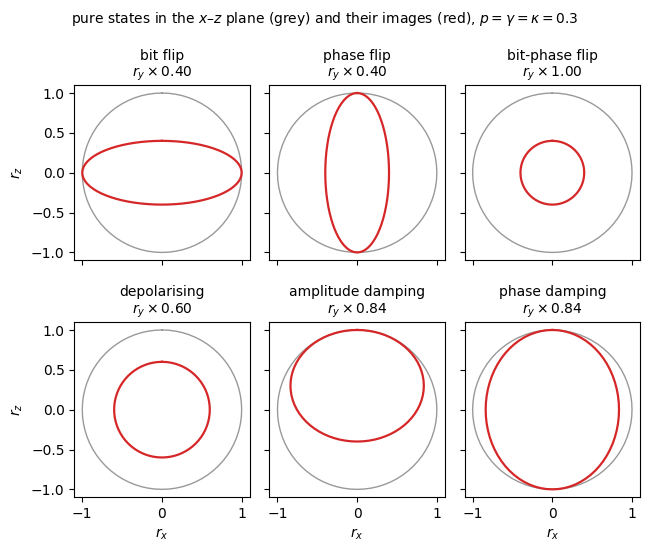

In [18]:
def dephasing(p): return [jnp.sqrt(1 - p) * I2, jnp.sqrt(p) * Z]
def depolarising(p): return [jnp.sqrt(1 - p) * I2] + [jnp.sqrt(p / 3) * P for P in (X, Y, Z)]
def amplitude_damping(gm): return [jnp.array([[1, 0], [0, jnp.sqrt(1 - gm)]], dtype=jnp.complex128),
                                   jnp.array([[0, jnp.sqrt(gm)], [0, 0]], dtype=jnp.complex128)]
P_NOISE = 0.3
for kr in (dephasing(P_NOISE), depolarising(P_NOISE), amplitude_damping(P_NOISE)):
    check_kraus(kr)
angles = np.linspace(0, 2 * np.pi, 73)
pure_states = [dm(jnp.cos(a / 2) * ket0 + jnp.sin(a / 2) * ket1) for a in angles]   # great circle in the x-z plane

def bit_flip(p): return [jnp.sqrt(1 - p) * I2, jnp.sqrt(p) * X]
def phase_flip(p): return dephasing(p)
def bit_phase_flip(p): return [jnp.sqrt(1 - p) * I2, jnp.sqrt(p) * Y]
def phase_damping(kappa): return [jnp.array([[1, 0], [0, jnp.sqrt(1 - kappa)]], dtype=jnp.complex128),
                                  jnp.array([[0, 0], [0, jnp.sqrt(kappa)]], dtype=jnp.complex128)]
s = 1 - 2 * P_NOISE; d = 1 - 4 * P_NOISE / 3; a = np.sqrt(1 - P_NOISE)
error_models = {   # name: (Kraus operators, expected Bloch map r -> r')
    "bit flip":          (bit_flip(P_NOISE),          lambda r: np.array([r[0], s * r[1], s * r[2]])),
    "phase flip":        (phase_flip(P_NOISE),        lambda r: np.array([s * r[0], s * r[1], r[2]])),
    "bit-phase flip":    (bit_phase_flip(P_NOISE),    lambda r: np.array([s * r[0], r[1], s * r[2]])),
    "depolarising":      (depolarising(P_NOISE),      lambda r: d * np.asarray(r)),
    "amplitude damping": (amplitude_damping(P_NOISE), lambda r: np.array([a * r[0], a * r[1], P_NOISE + (1 - P_NOISE) * r[2]])),
    "phase damping":     (phase_damping(P_NOISE),     lambda r: np.array([a * r[0], a * r[1], r[2]])),
}
# a random mixed test state from its own key, so the random streams of the other sections are unchanged
kr1, kr2 = jax.random.split(jax.random.PRNGKey(6612))
r_test = np.array(jax.random.uniform(kr1, (3,), minval=-1, maxval=1)); r_test = 0.9 * r_test / np.linalg.norm(r_test)
rho_test = 0.5 * (I2 + r_test[0] * X + r_test[1] * Y + r_test[2] * Z)
print(f"test Bloch vector {np.round(r_test, 3)}, p = gamma = kappa = {P_NOISE}")
for name, (kr, bmap) in error_models.items():
    check_kraus(kr)
    out = channel(rho_test, kr); check_density_matrix(out)
    assert np.allclose(np.asarray(bloch(out)), bmap(r_test), atol=1e-12), name
    print(f"{name:18s} {len(kr)} Kraus operators, sum K^dag K = I, Bloch vector -> {np.round(np.asarray(bloch(out)), 3)}")

# worked examples
p = P_NOISE
assert jnp.allclose(channel(dm(ket1), bit_flip(p)), jnp.diag(jnp.array([p, 1 - p])), atol=TOL)
assert jnp.allclose(channel(rho_plus, phase_flip(p)), 0.5 * jnp.array([[1, 1 - 2 * p], [1 - 2 * p, 1]]), atol=TOL)
assert jnp.allclose(channel(dm(ket1), amplitude_damping(p)), jnp.diag(jnp.array([p, 1 - p])), atol=TOL)
assert jnp.allclose(channel(rho_test, depolarising(p)), (1 - 4 * p / 3) * rho_test + (4 * p / 3) * I2 / 2, atol=TOL)
kappa = 1 - (1 - 2 * p) ** 2                     # phase damping equal to the phase flip
assert jnp.allclose(channel(rho_test, phase_damping(kappa)), channel(rho_test, phase_flip(p)), atol=TOL)
assert jnp.allclose(phase_damping(1 - np.cos(g / 2) ** 2)[0], K_env[0], atol=TOL)   # the controlled-rotation environment
print("|+> after the phase flip, p = 0.3        :", np.round(np.asarray(bloch(channel(rho_plus, phase_flip(p)))), 3))
print("|+> after amplitude damping, gamma = 0.3 :", np.round(np.asarray(bloch(channel(rho_plus, amplitude_damping(p)))), 3))
print("bit flip on |1>       :", np.round(np.asarray(channel(dm(ket1), bit_flip(p))).real, 3).tolist())
print("phase flip on |+>     :", np.round(np.asarray(channel(rho_plus, phase_flip(p))).real, 3).tolist())
print("amplitude damping |1> :", np.round(np.asarray(channel(dm(ket1), amplitude_damping(p))).real, 3).tolist())
print(f"phase damping with kappa = {kappa:.2f} equals the phase flip with p = {p}")

fig, axs = plt.subplots(2, 3, figsize=(6.6, 5.6), sharex=True, sharey=True)
for ax, (name, (kr, bmap)) in zip(axs.flat, error_models.items()):
    before = np.array([np.asarray(bloch(r)) for r in pure_states])
    after = np.array([np.asarray(bloch(channel(r, kr))) for r in pure_states])
    ax.plot(before[:, 0], before[:, 2], color="0.6", lw=1)
    ax.plot(after[:, 0], after[:, 2], color="C3", lw=1.6)
    ry = bmap(np.array([0.0, 1.0, 0.0]))[1]
    ax.set_title(f"{name}\n$r_y\\times{ry:.2f}$", fontsize=10); ax.set_aspect("equal")
for ax in axs[1]: ax.set_xlabel("$r_x$")
for ax in axs[:, 0]: ax.set_ylabel("$r_z$")
fig.suptitle(f"pure states in the $x$–$z$ plane (grey) and their images (red), $p=\\gamma=\\kappa={P_NOISE}$", fontsize=10)
fig.tight_layout(h_pad=1.2); save(fig, "fig_lab066_error_models"); plt.show()
NUMBERS["AmpDampOne"] = f"{p:.1f}"

fig_c, axs_c = plt.subplots(1, 3, figsize=(7.5, 2.8), sharey=True)
for ax, (name, kr) in zip(axs_c, [("dephasing", dephasing(P_NOISE)), ("depolarising", depolarising(P_NOISE)),
                                ("amplitude damping", amplitude_damping(P_NOISE))]):
    before = np.array([np.asarray(bloch(r)) for r in pure_states])
    after = np.array([np.asarray(bloch(channel(r, kr))) for r in pure_states])
    if name == "dephasing": expect = before * np.array([1 - 2 * P_NOISE, 1 - 2 * P_NOISE, 1])
    elif name == "depolarising": expect = before * (1 - 4 * P_NOISE / 3)
    else: expect = np.column_stack([np.sqrt(1 - P_NOISE) * before[:, 0], np.sqrt(1 - P_NOISE) * before[:, 1], P_NOISE + (1 - P_NOISE) * before[:, 2]])
    assert np.allclose(after, expect, atol=1e-12)
    ax.plot(before[:, 0], before[:, 2], color="0.6", lw=1, label="before")
    ax.plot(after[:, 0], after[:, 2], color="C3", lw=1.6, label="after")
    sym = "\\gamma" if name == "amplitude damping" else "p"
    ax.set_aspect("equal"); ax.set_title(f"{name}, ${sym}={P_NOISE}$"); ax.set_xlabel("$r_x$")
axs_c[0].set_ylabel("$r_z$"); axs_c[0].legend(loc="lower left", frameon=False, fontsize=9)
fig_c.tight_layout(); save(fig_c, "fig_lab066_channels"); plt.close(fig_c)   # three-panel subset of the six-panel figure, used in the lecture notes

Each panel shows how one error model deforms the cross-section of the Bloch ball in the $x$–$z$ plane. The factor that multiplies $r_y$ is written under the name of the model. The bit flip keeps the $x$ axis and squeezes $z$, and the phase flip keeps $z$ and squeezes $x$. The bit-phase flip squeezes both in this plane while it keeps $r_y$. Depolarising noise shrinks the circle uniformly, and amplitude damping shrinks it and moves it towards $|0\rangle$ at the top. Phase damping with $\kappa=0.3$ multiplies the coherences by $\sqrt{1-\kappa}\approx0.84$, a weaker effect than the factor $1-2p=0.4$ of the phase flip. The Pauli channels and depolarising noise keep the centre $\hat I/2$ fixed, and amplitude damping moves it, because the decay has the preferred final state $|0\rangle$.

### Damping channels from a master equation

Amplitude damping and phase damping arise after a time $t$ from a continuous decay described by the Lindblad master equation. A process with the jump operator $\hat L$ changes the density matrix as
$$\frac{d\hat\rho}{dt}=\hat L\hat\rho\hat L^\dagger-\tfrac12\{\hat L^\dagger\hat L,\hat\rho\}, \tag{20}$$
where $\{\hat A,\hat B\}=\hat A\hat B+\hat B\hat A$. The first term describes the jumps, and the anticommutator removes their probability from the evolution without a jump and keeps the trace at one. The loss of the excitation with the rate $\Gamma$ has the single jump operator
$$\hat L=\sqrt\Gamma\,\hat S^+,\qquad \hat S^+=|0\rangle\langle1| , \tag{21}$$
which takes the excited state $|1\rangle$ to the ground state $|0\rangle$. With $\hat L^\dagger\hat L=\Gamma|1\rangle\langle1|$ the population of $|1\rangle$ decays as $e^{-\Gamma t}$ and the coherence as $e^{-\Gamma t/2}$, which is amplitude damping with $\gamma=1-e^{-\Gamma t}$, so $\Gamma=1/T_1$. Pure dephasing with the rate $\gamma_\phi$ has the jump operator $\hat L=\sqrt{\gamma_\phi/2}\,\hat Z$ and $\hat L^\dagger\hat L=\frac{\gamma_\phi}2\hat I$, so equation (20) becomes
$$\frac{d\hat\rho}{dt}=\frac{\gamma_\phi}2\big(\hat Z\hat\rho \hat Z-\hat\rho\big). \tag{22}$$
It leaves the populations unchanged and multiplies the coherence by $e^{-\gamma_\phi t}$, which is phase damping with $\sqrt{1-\kappa}=e^{-\gamma_\phi t}$. The code integrates both equations with small Runge–Kutta steps and compares the results with the Kraus channels.

In [19]:
S_plus = np.array([[0, 1], [0, 0]], dtype=complex)      # S^+ = |0><1|; the jump operator is L = sqrt(Gamma) S^+
Zn = np.asarray(Z)
def lindblad_rhs(rho, Gam, Gphi):
    L = np.sqrt(Gam) * S_plus; LdL = L.conj().T @ L
    amp = L @ rho @ L.conj().T - 0.5 * (LdL @ rho + rho @ LdL)
    deph = 0.5 * Gphi * (Zn @ rho @ Zn - rho)
    return amp + deph
def integrate(rho0, Gam, Gphi, t, steps=400):
    rho, dt = np.asarray(rho0, dtype=complex), t / steps
    for _ in range(steps):
        k1 = lindblad_rhs(rho, Gam, Gphi); k2 = lindblad_rhs(rho + dt / 2 * k1, Gam, Gphi)
        k3 = lindblad_rhs(rho + dt / 2 * k2, Gam, Gphi); k4 = lindblad_rhs(rho + dt * k3, Gam, Gphi)
        rho = rho + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return rho
Gam, Gphi, t_l = 0.7, 0.4, 1.3
rho0 = np.asarray(rho_test)
amp_ode = integrate(rho0, Gam, 0.0, t_l)
assert np.allclose(amp_ode, np.asarray(channel(rho_test, amplitude_damping(1 - np.exp(-Gam * t_l)))), atol=1e-10)
deph_ode = integrate(rho0, 0.0, Gphi, t_l)
assert np.allclose(deph_ode, np.asarray(channel(rho_test, phase_damping(1 - np.exp(-2 * Gphi * t_l)))), atol=1e-10)
print(f"Lindblad decay with Gamma t = {Gam * t_l:.2f} equals amplitude damping with gamma = 1 - exp(-Gamma t) = {1 - np.exp(-Gam * t_l):.3f}")
print(f"pure dephasing with gamma_phi t = {Gphi * t_l:.2f} equals phase damping with sqrt(1 - kappa) = exp(-gamma_phi t) = {np.exp(-Gphi * t_l):.3f}")


Lindblad decay with Gamma t = 0.91 equals amplitude damping with gamma = 1 - exp(-Gamma t) = 0.597
pure dephasing with gamma_phi t = 0.52 equals phase damping with sqrt(1 - kappa) = exp(-gamma_phi t) = 0.595


### The register under local noise

Each qubit of the Bell register now suffers the same noise independently, $\hat\rho\to\sum_{k,l}(\hat K_k\otimes \hat K_l)\,\hat\rho\,(\hat K_k\otimes \hat K_l)^\dagger$. We follow the three correlators and the purity of the register as the noise strength $p$ grows, together with the reduced state of qubit 0.

at p = 0.3: dephasing <XX> = 0.160, register purity = 0.513; depolarising <XX> = 0.360, register purity = 0.347


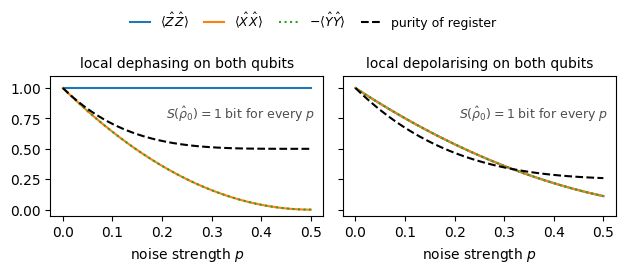

In [20]:
def local_noise(rho4, kraus):
    return sum(jnp.kron(Ka, Kb) @ rho4 @ jnp.kron(Ka, Kb).conj().T for Ka in kraus for Kb in kraus)

ps = np.linspace(0, 0.5, 51)
rows = {"dephasing": [], "depolarising": []}
for name, fam in [("dephasing", dephasing), ("depolarising", depolarising)]:
    for p in ps:
        r = local_noise(rho_bell, fam(p))
        rows[name].append([expval(r, ZZ), expval(r, XX), expval(r, YY), purity(r), entropy_bits(ptrace_dm(r, 0))])
    rows[name] = np.array(rows[name])
assert np.allclose(rows["dephasing"][:, 0], 1) and np.allclose(rows["dephasing"][:, 1], (1 - 2 * ps) ** 2)
assert np.allclose(rows["depolarising"][:, 1], (1 - 4 * ps / 3) ** 2) and np.allclose(rows["depolarising"][:, 0], (1 - 4 * ps / 3) ** 2)
assert np.allclose(rows["dephasing"][:, 4], 1) and np.allclose(rows["depolarising"][:, 4], 1)

fig, axs = plt.subplots(1, 2, figsize=(6.27, 2.75), sharey=True)      # final size: 0.95 of a 6.6 in text width
for ax, name in zip(axs, ["dephasing", "depolarising"]):
    d = rows[name]
    ax.plot(ps, d[:, 0], label="$\\langle\\hat Z\\hat Z\\rangle$"); ax.plot(ps, d[:, 1], label="$\\langle\\hat X\\hat X\\rangle$")
    ax.plot(ps, -d[:, 2], ls=":", label="$-\\langle\\hat Y\\hat Y\\rangle$"); ax.plot(ps, d[:, 3], ls="--", color="k", label="purity of register")
    ax.text(0.97, 0.70, "$S(\\hat\\rho_0)=1$ bit for every $p$", fontsize=9, color="0.3", ha="right", transform=ax.transAxes)
    ax.set_title(f"local {name} on both qubits"); ax.set_xlabel("noise strength $p$")
axs[0].set_ylim(-0.05, 1.1)
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=9, frameon=False, columnspacing=1.2, handlelength=1.6); save(fig, "fig_lab066_register_noise"); plt.show()
i3 = int(np.argmin(abs(ps - P_NOISE)))
NUMBERS["NoiseP"] = f"{P_NOISE}"
NUMBERS["XXDephasing"] = f"{rows['dephasing'][i3, 1]:.2f}"
NUMBERS["XXDepolarising"] = f"{rows['depolarising'][i3, 1]:.2f}"
NUMBERS["PurityDephasing"] = f"{rows['dephasing'][i3, 3]:.2f}"
print(f"at p = {P_NOISE}: dephasing <XX> = {rows['dephasing'][i3, 1]:.3f}, register purity = {rows['dephasing'][i3, 3]:.3f}; "
      f"depolarising <XX> = {rows['depolarising'][i3, 1]:.3f}, register purity = {rows['depolarising'][i3, 3]:.3f}")

Local dephasing leaves $\langle \hat Z\hat Z\rangle=1$, because populations in the $\hat Z$ basis are untouched, and reduces $\langle \hat X\hat X\rangle=(1-2p)^2$ and $\langle \hat Y\hat Y\rangle$. At $p=1/2$ the register has become the classical correlated coin. Depolarising noise reduces all three correlators by the same factor $(1-4p/3)^2$, so in the right panel the curve of $\langle \hat Z\hat Z\rangle$ lies under that of $\langle \hat X\hat X\rangle$. In both cases the purity of the register falls.

The entropy of qubit 0, written in each panel, stays at one bit for every $p$, because $\hat\rho_0=\hat I/2$ throughout. For a mixed register the reduced entropy no longer measures entanglement. It misses the transition from the Bell state to the classical coin, which the correlators and the purity of the register reveal. The partial transpose, treated in Lab 066a, detects the entanglement of such mixed states.

## 11. Noise in quantum circuits

A quantum computer runs a circuit, a sequence of gates followed by a measurement of every qubit, and each step adds noise. We assemble the channels of Section 10 into the standard model of a noisy circuit, simulate it with density matrices and apply it to the preparation of a GHZ state.

### 11.1 The standard circuit noise model

Each gate is modelled as the ideal unitary followed by a noise channel on the qubits that the gate touched. After a one-qubit gate we apply one-qubit depolarising noise with probability $p_1$, $\hat\rho\to(1-p_1)\hat\rho+\frac{p_1}3(\hat X\hat\rho \hat X+\hat Y\hat\rho \hat Y+\hat Z\hat\rho \hat Z)$. After a two-qubit gate such as CNOT we apply two-qubit depolarising noise with probability $p_2$. Each of the 15 Pauli strings $\hat P\neq \hat I\hat I$ of the two qubits then occurs with probability $p_2/15$,
$$\hat\rho\to(1-p_2)\,\hat\rho+\frac{p_2}{15}\sum_{P\neq II}\hat P\hat\rho \hat P=\Big(1-\tfrac{16}{15}p_2\Big)\hat\rho+\tfrac{16}{15}p_2\,\frac{\hat I}4 . \tag{23}$$
The second form follows from $\sum_{\text{all }16\ P}\hat P\hat\rho \hat P=4\,\mathrm{Tr}(\hat\rho)\,\hat I$ for two qubits and shows that the channel mixes the state with the maximally mixed state $\hat I/4$. Entangling gates are the least accurate operations of current devices, and $p_2$ is often about ten times larger than $p_1$.

In every layer of the circuit the qubits that take no part in the gate of that layer wait and decohere. During a waiting time $t$ a qubit suffers amplitude damping with $\gamma=1-e^{-t/T_1}$ and pure dephasing. Together they make the coherences decay as $e^{-t/T_2}$, with the relaxation time $T_1$ and the coherence time $T_2$. We model one layer of waiting by amplitude damping with $\gamma$ followed by phase damping with $\kappa$ on the waiting qubits. The active qubits of that layer receive the gate noise.

The readout itself makes errors. With probability $\epsilon_{0\to1}$ a qubit in $|0\rangle$ is reported as 1, and with probability $\epsilon_{1\to0}$ a qubit in $|1\rangle$ is reported as 0. The second error is often larger, because the excitation can decay during the measurement. The measured probabilities follow from the true ones by the confusion matrix, also called the assignment matrix,
$$\begin{pmatrix}p_{\rm meas}(0)\\p_{\rm meas}(1)\end{pmatrix}=A\begin{pmatrix}p(0)\\p(1)\end{pmatrix},\qquad A=\begin{pmatrix}1-\epsilon_{0\to1}&\epsilon_{1\to0}\\ \epsilon_{0\to1}&1-\epsilon_{1\to0}\end{pmatrix}, \tag{24}$$
which is the noisy-detector POVM of Section 9 with $\hat\pi_0=(1-\epsilon_{0\to1})|0\rangle\langle0|+\epsilon_{1\to0}|1\rangle\langle1|$. For independent readout errors on $N$ qubits the matrix acting on the $2^N$ bit-string probabilities is the Kronecker product $A\otimes A\otimes\dots\otimes A$, in the bit-string order of the state vector.

All these errors are stochastic, each occurring with some probability. Over $n$ gates their probabilities add, and the error grows as $np$ while it is small. A miscalibrated pulse that rotates by $\theta+\epsilon$ in place of $\theta$ is a coherent, unitary error. Over $n$ repetitions the small angles add in the amplitude, so the error probability grows as $(n\epsilon)^2/4$. Coherent errors are therefore more harmful in long circuits, although a single gate has the same error probability $\sin^2(\epsilon/2)$ in both cases.

### 11.2 Density-matrix simulation of a circuit

A noisy circuit acts on the density matrix of the register. Each gate $\hat U$ maps $\hat\rho\to \hat U\hat\rho \hat U^\dagger$, and each noise channel maps $\hat\rho\to\sum_k\hat K_k\hat\rho \hat K_k^\dagger$. A channel on a few qubits of a larger register is built with Kronecker products and stored as a sparse matrix with `scipy.sparse`. A Kraus operator on one or two of $N$ qubits has at most $2\cdot2^N$ or $4\cdot2^N$ nonzero entries out of $4^N$. A one-qubit Kraus operator $\hat K$ on qubit $q$ becomes $\hat I\otimes\dots\otimes \hat K\otimes\dots\otimes \hat I$, and a two-qubit Kraus operator on the neighbouring qubits $(q,q+1)$ takes the place of the two factors. The efficient version reshapes $\hat\rho$ into a tensor with $N$ ket and $N$ bra indices. It contracts $\hat K$ with the ket indices and $\hat K^*$ with the bra indices of the chosen qubits, for any set of qubits. The code checks that both versions agree, that every channel is complete, $\sum_k\hat K_k^\dagger \hat K_k=\hat I$, and that it preserves the trace.

The density matrix of $N$ qubits has $4^N$ entries, which limits this exact simulation to about a dozen qubits. A cheaper alternative keeps a state vector and samples the noise. In each run, a Pauli error drawn with the probabilities of the depolarising channel follows every gate. The average of $|\psi\rangle\langle\psi|$ over many such quantum trajectories approximates the density matrix, with a statistical error that falls as one over the square root of the number of trajectories.

In [21]:
import string
from functools import reduce
PAULI_1Q = [I2, X, Y, Z]
PAULI_2Q = [jnp.kron(A_, B_) for A_ in PAULI_1Q for B_ in PAULI_1Q]          # II, IX, ..., ZZ

def depol1(p):
    return [jnp.sqrt(1 - p) * I2] + [jnp.sqrt(p / 3) * P for P in (X, Y, Z)]

def depol2(p):
    return [jnp.sqrt(1 - p) * PAULI_2Q[0]] + [jnp.sqrt(p / 15) * P for P in PAULI_2Q[1:]]

def idle(gamma, kappa):
    # amplitude damping followed by phase damping, combined into one Kraus set
    return [Kp @ Ka for Kp in phase_damping(kappa) for Ka in amplitude_damping(gamma)]

import scipy.sparse as sp

def embed(K, q, N):
    # sparse Kronecker product: K on qubit q (2x2) or on the neighbouring qubits (q, q+1) (4x4), identities elsewhere
    k = int(np.log2(K.shape[0]))
    left = sp.identity(2 ** q, dtype=complex, format="csr"); right = sp.identity(2 ** (N - q - k), dtype=complex, format="csr")
    return sp.kron(sp.kron(left, sp.csr_matrix(np.asarray(K)), format="csr"), right, format="csr")

def apply_channel_kron(rho, Ks, q, N):
    rho = np.asarray(rho)
    out = 0
    for K in Ks:
        Kf = embed(K, q, N)
        out = out + Kf @ (Kf @ rho.conj().T).conj().T          # K rho K^dagger with sparse K
    return out

def apply_channel_einsum(rho, Ks, qubits, N):
    # contract K with the ket indices and K* with the bra indices of the chosen qubits
    letters = string.ascii_lowercase                  # 26 letters: N ket and N bra labels
    if 2 * N > len(letters):
        raise ValueError(f"apply_channel_einsum supports at most {len(letters) // 2} qubits")
    L = letters[:N]; R = letters[N:2 * N]
    kin = "".join(L[q] for q in qubits); kout = "".join(L[q].upper() for q in qubits)
    bin_ = "".join(R[q] for q in qubits); bout = "".join(R[q].upper() for q in qubits)
    out_l = "".join(L[q].upper() if q in qubits else L[q] for q in range(N))
    out_r = "".join(R[q].upper() if q in qubits else R[q] for q in range(N))
    k = len(qubits); t = rho.reshape((2,) * (2 * N)); out = 0
    for K in Ks:
        Kt = K.reshape((2,) * (2 * k))
        out = out + jnp.einsum(f"{kout}{kin},{L}{R},{bout}{bin_}->{out_l}{out_r}", Kt, t, Kt.conj())
    return out.reshape(2 ** N, 2 ** N)

def apply_unitary(rho, U, q, N):
    Uf = embed(U, q, N)
    return Uf @ (Uf @ np.asarray(rho).conj().T).conj().T          # U rho U^dagger with sparse U

# checks: sparse embedding = dense Kronecker product; completeness, trace preservation, Kronecker form = einsum form
for K, q, N_ in ((X, 1, 3), (jnp.kron(X, Z), 1, 4), (Y, 0, 5)):
    k_ = int(np.log2(K.shape[0]))
    assert np.allclose(embed(K, q, N_).toarray(), np.asarray(reduce(jnp.kron, [I2] * q + [K] + [I2] * (N_ - q - k_))))
    assert embed(K, q, N_).nnz <= K.shape[0] * 2 ** N_
print(f"a one-qubit Kraus operator on 10 qubits: nnz = {embed(X, 4, 10).nnz:,d} of {4 ** 10:,d} entries")
p1, p2, gam, kap = 0.003, 0.03, 0.002, 0.004
NUMBERS["IdleGamma"] = f"{gam}"; NUMBERS["IdleKappa"] = f"{kap}"
for Ks in (depol1(p1), depol2(p2), idle(gam, kap)):
    d = Ks[0].shape[0]
    assert jnp.allclose(sum(K.conj().T @ K for K in Ks), jnp.eye(d), atol=TOL)
kq1, kq2 = jax.random.split(jax.random.PRNGKey(6611))                    # own key for these checks
G = jax.random.normal(kq1, (8, 8)) + 1j * jax.random.normal(kq2, (8, 8))
rho_r = G @ G.conj().T; rho_r = rho_r / jnp.trace(rho_r)                     # a random mixed state of 3 qubits
for Ks, q, qs in ((depol1(0.2), 1, (1,)), (idle(0.3, 0.2), 2, (2,)), (depol2(0.3), 0, (0, 1)), (depol2(0.3), 1, (1, 2))):
    out_k = apply_channel_kron(rho_r, Ks, q, 3)
    assert jnp.allclose(out_k, apply_channel_einsum(rho_r, Ks, qs, 3), atol=1e-12)
    assert abs(jnp.trace(out_k) - 1) < 1e-12
# the two forms of two-qubit depolarising noise
rho2 = rho_r.reshape(2, 4, 2, 4)[0, :, 0, :]; rho2 = rho2 / jnp.trace(rho2)
assert jnp.allclose(sum(P @ rho2 @ P.conj().T for P in PAULI_2Q), 4 * jnp.eye(4), atol=1e-12)
assert jnp.allclose(apply_channel_kron(rho2, depol2(0.3), 0, 2), (1 - 16 * 0.3 / 15) * rho2 + 16 * 0.3 / 15 * jnp.eye(4) / 4, atol=1e-12)
print("all channels complete and trace preserving; Kronecker and einsum forms agree; depol2 = mixing with I/4")


a one-qubit Kraus operator on 10 qubits: nnz = 1,024 of 1,048,576 entries
all channels complete and trace preserving; Kronecker and einsum forms agree; depol2 = mixing with I/4


### 11.3 A noisy GHZ preparation

The GHZ state $|{\rm GHZ}_N\rangle=(|0\dots0\rangle+|1\dots1\rangle)/\sqrt2$ is prepared from $|0\dots0\rangle$ by $\hat H$ on qubit 0 followed by the chain $\widehat{\mathrm{CNOT}}_{0\to1},\widehat{\mathrm{CNOT}}_{1\to2},\dots,\widehat{\mathrm{CNOT}}_{N-2\to N-1}$. In the noisy simulation every gate is followed by its depolarising channel, and in every layer the qubits outside the gate suffer the idle channel. We use $p_1=0.003$, $p_2=0.03$, $\gamma=0.002$ and $\kappa=0.004$ per layer, and the readout errors $\epsilon_{0\to1}=0.01$ and $\epsilon_{1\to0}=0.03$. These illustrative values are of the order found on current devices and belong to no particular machine.

The fidelity with the ideal state is $F=\langle{\rm GHZ}_N|\hat\rho|{\rm GHZ}_N\rangle$, the probability that the noisy register passes a test for the target state. The bit-string probabilities after the readout errors show how much weight leaks out of the two ideal strings $0\dots0$ and $1\dots1$. The parity $\langle \hat Z_0\hat Z_{N-1}\rangle$ of the first and the last qubit, computed from the measured bit strings, equals one in the ideal state. A rough estimate counts each gate as failing with its error probability, $F\approx(1-p_1)(1-p_2)^{N-1}$. The estimate is approximate, because some Pauli errors, such as $\hat Z\otimes \hat Z$ after a CNOT, leave the GHZ state unchanged, and because it ignores idle noise.

Panel (b) of the figure compares the two kinds of error of Section 11.1. A qubit starts in $|0\rangle$ and receives $n$ small rotations, each $\hat R_x(\epsilon)$ in the coherent case and a bit flip with the same probability $\sin^2(\epsilon/2)$ in the stochastic case. Finally, we compare the density-matrix simulation of the three-qubit circuit with an average over quantum trajectories. This check covers the gate noise alone, without idle damping and without readout errors, and it reports the statistical error of the trajectory estimate of the fidelity.

Predict the rough estimate $(1-p_1)(1-p_2)^{N-1}$ for $N=4$, and whether the full simulation lies above or below it, before running the code.

N = 2: 1 CNOTs, F = 0.974 (estimate 0.967), leakage after readout = 0.054, <Z_0 Z_N-1> = 0.893
N = 3: 2 CNOTs, F = 0.945 (estimate 0.938), leakage after readout = 0.096, <Z_0 Z_N-1> = 0.862
N = 4: 3 CNOTs, F = 0.915 (estimate 0.910), leakage after readout = 0.136, <Z_0 Z_N-1> = 0.833
N = 5: 4 CNOTs, F = 0.884 (estimate 0.883), leakage after readout = 0.176, <Z_0 Z_N-1> = 0.805
gate noise only, trajectories (T = 3000): F = 0.940 +- 0.004, density matrix: F = 0.947, largest entry difference 0.006


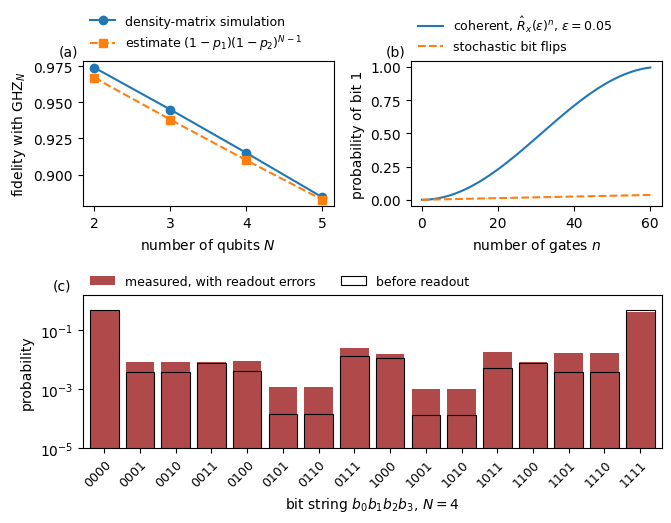

In [22]:
CNOT_ = jnp.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=jnp.complex128)
eps0, eps1 = 0.01, 0.03
A_read = jnp.array([[1 - eps0, eps1], [eps0, 1 - eps1]])

def noisy_ghz(N, p1, p2, gam, kap):
    rho = jnp.zeros((2 ** N, 2 ** N), dtype=jnp.complex128).at[0, 0].set(1)
    rho = apply_unitary(rho, H, 0, N); rho = apply_channel_kron(rho, depol1(p1), 0, N)
    for q in range(1, N):
        rho = apply_channel_kron(rho, idle(gam, kap), q, N)               # the other qubits wait
    for k in range(N - 1):
        rho = apply_unitary(rho, CNOT_, k, N); rho = apply_channel_kron(rho, depol2(p2), k, N)
        for q in range(N):
            if q not in (k, k + 1):
                rho = apply_channel_kron(rho, idle(gam, kap), q, N)
    return rho

def measured_probabilities(rho, N):
    p_true = jnp.real(jnp.diag(rho))
    return reduce(jnp.kron, [A_read] * N) @ p_true                        # confusion matrix A (x) ... (x) A

Ns = [2, 3, 4, 5]
fid, est, leak, parity = [], [], [], []
for N in Ns:
    ghz = jnp.zeros(2 ** N, dtype=jnp.complex128).at[0].set(1 / jnp.sqrt(2.0)).at[-1].set(1 / jnp.sqrt(2.0))
    ideal = apply_unitary(jnp.zeros((2 ** N, 2 ** N), dtype=jnp.complex128).at[0, 0].set(1), H, 0, N)
    for k in range(N - 1):
        ideal = apply_unitary(ideal, CNOT_, k, N)
    assert jnp.allclose(ideal, dm(ghz), atol=1e-12)                       # noiseless circuit gives GHZ_N
    rho = noisy_ghz(N, p1, p2, gam, kap)
    check_density_matrix(rho)
    fid.append(float(jnp.real(ghz.conj() @ rho @ ghz))); est.append((1 - p1) * (1 - p2) ** (N - 1))
    pm = np.asarray(measured_probabilities(rho, N))
    assert abs(pm.sum() - 1) < 1e-12
    leak.append(1 - pm[0] - pm[-1])
    sign = np.array([(-1) ** (((i >> (N - 1)) & 1) + (i & 1)) for i in range(2 ** N)])
    parity.append(float(pm @ sign))
    if N == 4: pm4, p_true4 = pm, np.asarray(jnp.real(jnp.diag(rho)))
    print(f"N = {N}: {N - 1} CNOTs, F = {fid[-1]:.3f} (estimate {est[-1]:.3f}), leakage after readout = {leak[-1]:.3f}, <Z_0 Z_N-1> = {parity[-1]:.3f}")

# coherent versus stochastic errors on one qubit
eps_c = 0.05; ns = np.arange(0, 61)
p_coh = np.sin(ns * eps_c / 2) ** 2                                       # R_x(eps)^n |0> = R_x(n eps)|0>
q_flip = np.sin(eps_c / 2) ** 2
p_sto = (1 - (1 - 2 * q_flip) ** ns) / 2                                  # n independent bit flips
psi = ket0
for _ in range(10):
    psi = jnp.array([[np.cos(eps_c / 2), -1j * np.sin(eps_c / 2)], [-1j * np.sin(eps_c / 2), np.cos(eps_c / 2)]]) @ psi
assert abs(abs(psi[1]) ** 2 - p_coh[10]) < 1e-12
rho_s = dm(ket0)
for _ in range(10):
    rho_s = channel(rho_s, bit_flip(q_flip))
assert abs(float(jnp.real(rho_s[1, 1])) - p_sto[10]) < 1e-12

# quantum trajectories for the three-qubit circuit with gate noise only
N3, T = 3, 3000
rng = np.random.default_rng(66)
P1n = [np.asarray(P) for P in (X, Y, Z)]; P2n = [np.asarray(P) for P in PAULI_2Q[1:]]
def full(U, q, N): return embed(jnp.asarray(U), q, N)            # sparse operator on the full register
H_full = full(H, 0, N3); C_full = [full(CNOT_, k, N3) for k in range(N3 - 1)]
P1_full = [full(P, 0, N3) for P in P1n]; P2_full = [[full(P, k, N3) for P in P2n] for k in range(N3 - 1)]
rho_traj = np.zeros((8, 8), dtype=complex); f_runs = np.zeros(T)
ghz3 = np.zeros(8); ghz3[[0, 7]] = 1 / np.sqrt(2)
for t_run in range(T):
    v = np.zeros(8, dtype=complex); v[0] = 1
    v = H_full @ v
    if rng.random() < p1: v = P1_full[rng.integers(3)] @ v
    for k in range(N3 - 1):
        v = C_full[k] @ v
        if rng.random() < p2: v = P2_full[k][rng.integers(15)] @ v
    rho_traj += np.outer(v, v.conj()) / T
    f_runs[t_run] = abs(ghz3 @ v) ** 2
rho_exact = np.asarray(noisy_ghz(N3, p1, p2, 0.0, 0.0))
F_traj, F_exact = float(np.real(ghz3 @ rho_traj @ ghz3)), float(np.real(ghz3 @ rho_exact @ ghz3))
dev = float(np.max(np.abs(rho_traj - rho_exact)))
assert dev < 5 / np.sqrt(T)
se_traj = float(np.std(f_runs, ddof=1) / np.sqrt(T))          # statistical error of the trajectory fidelity
assert abs(float(np.mean(f_runs)) - F_traj) < 1e-12 and abs(F_traj - F_exact) < 4 * se_traj + 1e-12
print(f"gate noise only, trajectories (T = {T}): F = {F_traj:.3f} +- {se_traj:.3f}, density matrix: F = {F_exact:.3f}, largest entry difference {dev:.3f}")

def panel_fidelity(ax):
    ax.plot(Ns, fid, "o-", label="density-matrix simulation"); ax.plot(Ns, est, "s--", label=r"estimate $(1-p_1)(1-p_2)^{N-1}$")
    ax.set_xticks(Ns); ax.set_xlabel("number of qubits $N$"); ax.set_ylabel(r"fidelity with GHZ$_N$")
    ax.legend(fontsize=9, frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.0), borderaxespad=0.2)

def panel_coherent(ax):
    ax.plot(ns, p_coh, label=rf"coherent, $\hat R_x(\epsilon)^n$, $\epsilon={eps_c}$"); ax.plot(ns, p_sto, "--", label="stochastic bit flips")
    ax.set_xlabel("number of gates $n$"); ax.set_ylabel("probability of bit 1")
    ax.legend(fontsize=9, frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.0), borderaxespad=0.2)

def panel_bits(ax):
    labels4 = [format(i, "04b") for i in range(16)]
    ax.bar(np.arange(16), pm4, color="#b04a4a", label="measured, with readout errors")
    ax.bar(np.arange(16), p_true4, color="none", edgecolor="k", lw=0.8, label="before readout")
    ax.set_yscale("log"); ax.set_ylim(1e-5, 1.5); ax.set_xlim(-0.6, 15.6)
    ax.set_xticks(np.arange(16), labels4, rotation=45, ha="right", rotation_mode="anchor", fontsize=9)
    ax.set_xlabel("bit string $b_0b_1b_2b_3$, $N=4$"); ax.set_ylabel("probability")
    ax.legend(fontsize=9, frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2, borderaxespad=0.2)

fig = plt.figure(figsize=(6.6, 5.2), layout="constrained")             # final size: the full 6.6 in text width
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
ax_a, ax_b, ax_c = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
panel_fidelity(ax_a); panel_coherent(ax_b); panel_bits(ax_c)
for ax, lab in ((ax_a, "(a)"), (ax_b, "(b)"), (ax_c, "(c)")):
    ax.text(-0.02, 1.02, lab, transform=ax.transAxes, fontsize=10, ha="right", va="bottom")
fig.get_layout_engine().set(h_pad=0.08, hspace=0.06)
with plt.rc_context({"savefig.bbox": "standard"}):
    fig.savefig(FIG / "fig_lab066_circuit_noise.pdf"); fig.savefig(FIG / "fig_lab066_circuit_noise.png", dpi=150)
plt.show()
# the three panels also as separate files, for slides
for name, panel, size in (("fidelity", panel_fidelity, (3.2, 2.5)), ("coherent", panel_coherent, (3.2, 2.5)), ("bits", panel_bits, (5.0, 2.6))):
    f1, a1 = plt.subplots(figsize=size, layout="constrained"); panel(a1)
    with plt.rc_context({"savefig.bbox": "standard"}):
        f1.savefig(FIG / f"fig_lab066_circuit_noise_{name}.pdf"); f1.savefig(FIG / f"fig_lab066_circuit_noise_{name}.png", dpi=150)
    plt.close(f1)
NUMBERS.update(CircPOne=f"{p1}", CircPTwo=f"{p2}", ReadEpsZero=f"{eps0}", ReadEpsOne=f"{eps1}",
               FidGHZFour=f"{fid[2]:.3f}", FidGHZFourEst=f"{est[2]:.3f}", LeakGHZFour=f"{leak[2]:.3f}",
               ParityGHZFour=f"{parity[2]:.3f}", FidGHZFive=f"{fid[3]:.3f}", Trajectories=str(T),
               CohPSixty=f"{p_coh[-1]:.3f}", StoPSixty=f"{p_sto[-1]:.3f}")


Panel (a) shows the fidelity of the noisy GHZ preparation falling with the number of qubits. Every additional qubit adds one CNOT with its two-qubit noise and one more layer of idle noise on the waiting qubits. The estimate $(1-p_1)(1-p_2)^{N-1}$ lies slightly below the simulation, since it counts as failures the Pauli errors that leave the GHZ state unchanged. The idle noise, which the estimate ignores, pulls the simulation down a little. Panel (c) shows, on a logarithmic scale, the bit-string probabilities for $N=4$. Almost all weight stays on $0000$ and $1111$. The gate errors put a few per mille on other strings, marked by black outlines. The readout errors raise the strings with one wrong bit, such as $0001$ and $1110$, above that level.

The printed parities $\langle \hat Z_0\hat Z_{N-1}\rangle$ of the measured bit strings fall further below one as $N$ grows, through the gate errors and the readout errors of the two outer qubits. Panel (b) compares $n$ coherent rotations by $\epsilon$ with $n$ bit flips of the same single-gate probability. The stochastic error grows linearly and the coherent one quadratically, and after 60 gates the coherent error is far larger. For the gate-noise model the trajectory fidelity agrees with the density-matrix fidelity within a few of its standard errors. The core route ends here.

## 12. Fidelity and trace distance

For two pure states the fidelity is the overlap probability $F=|\langle\varphi|\psi\rangle|^2$, which equals one for equal states up to a global phase and zero for orthogonal ones. For density matrices the Uhlmann fidelity generalises it,
$$F(\hat\rho,\hat\sigma)=\Big(\mathrm{Tr}\sqrt{\sqrt{\hat\rho}\,\hat\sigma\sqrt{\hat\rho}}\Big)^2, \tag{25}$$
where $\sqrt{\hat A}$ of a positive matrix takes the square root of each eigenvalue and keeps the eigenvectors. When one of the two states is pure, $\hat\rho=|\psi\rangle\langle\psi|$, it reduces to $F=\langle\psi|\hat\sigma|\psi\rangle$, the probability that $\hat\sigma$ passes a test for $|\psi\rangle$.

The trace distance
$$D(\hat\rho,\hat\sigma)=\tfrac12\|\hat\rho-\hat\sigma\|_1=\tfrac12\sum_k|\mu_k| , \tag{26}$$
with $\mu_k$ the eigenvalues of $\hat\rho-\hat\sigma$, has a direct meaning for state discrimination. Given one copy that is $\hat\rho$ or $\hat\sigma$ with equal probability, the best possible measurement identifies it correctly with probability $\tfrac12(1+D)$. For one qubit $D$ is half the distance between the two Bloch vectors. The three pairs evaluated below are $|+\rangle$ and the 50/50 mixture, the Bell state and the classical coin, and the Bell state before and after local dephasing with $p=0.3$. Fidelities with a target state and distances between estimated and true states measure the quality of state preparation and of tomography.

In [23]:
def psd_sqrt(A):
    # square root of a positive semidefinite Hermitian matrix from its eigendecomposition
    w, V = np.linalg.eigh(np.asarray(A))
    return (V * np.sqrt(np.clip(w, 0, None))) @ V.conj().T

def fidelity(rho, sigma):
    r = psd_sqrt(rho)
    return float(np.real(np.trace(psd_sqrt(r @ np.asarray(sigma) @ r))) ** 2)

def trace_distance(rho, sigma):
    return float(0.5 * np.sum(np.abs(np.linalg.eigvalsh(np.asarray(rho - sigma)))))

rho_bell_noisy = local_noise(rho_bell, dephasing(P_NOISE))
pairs = [("|+> vs 50/50 mixture", rho_plus, rho_mix, plus),
         ("Bell vs classical coin", rho_bell, rho_coin, phi_plus),
         (f"Bell vs Bell with dephasing p={P_NOISE}", rho_bell, rho_bell_noisy, phi_plus)]
print("pair                                fidelity  <psi|sigma|psi>  trace distance  best success probability")
for name, rho, sigma, psi in pairs:
    F = fidelity(rho, sigma); Fp = float(jnp.real(psi.conj() @ sigma @ psi)); D = trace_distance(rho, sigma)
    assert abs(F - Fp) < 1e-8
    print(f"{name:35s} {F:.3f}     {Fp:.3f}            {D:.3f}           {0.5 * (1 + D):.3f}")
assert abs(fidelity(rho_bell, rho_coin) - 0.5) < 1e-8 and abs(trace_distance(rho_bell, rho_coin) - 0.5) < 1e-12
assert abs(fidelity(rho_bell, rho_bell_noisy) - 0.5 * (1 + (1 - 2 * P_NOISE) ** 2)) < 1e-8
rp, rm = np.asarray(bloch(rho_plus)), np.asarray(bloch(rho_mix))
assert abs(trace_distance(rho_plus, rho_mix) - 0.5 * np.linalg.norm(rp - rm)) < 1e-12
NUMBERS["FidBellCoin"] = f"{fidelity(rho_bell, rho_coin):.2f}"
NUMBERS["FidBellNoisy"] = f"{fidelity(rho_bell, rho_bell_noisy):.2f}"
NUMBERS["DistBellNoisy"] = f"{trace_distance(rho_bell, rho_bell_noisy):.2f}"
NUMBERS["SuccBellNoisy"] = f"{0.5 * (1 + trace_distance(rho_bell, rho_bell_noisy)):.2f}"


pair                                fidelity  <psi|sigma|psi>  trace distance  best success probability
|+> vs 50/50 mixture                0.500     0.500            0.500           0.750
Bell vs classical coin              0.500     0.500            0.500           0.750
Bell vs Bell with dephasing p=0.3   0.580     0.580            0.420           0.710


The Bell state and the classical coin have fidelity one half and trace distance one half. A single copy is therefore identified correctly with probability $3/4$ at best, for example by measuring $\hat X\hat X$. After local dephasing with $p=0.3$ the fidelity with the Bell state is $\tfrac12\big(1+(1-2p)^2\big)=0.58$, the probability that the noisy register passes a test for $|\Phi^+\rangle$.

## 13. Exercises

1. Compute $\hat\rho_0$ and $\hat\rho_1$ of $(|01\rangle-|10\rangle)/\sqrt2$ with all three methods, and find the correlators that distinguish it from $|\Phi^+\rangle$.
2. Show with $\Psi=\mathbf u\mathbf v^T$ that the reduced state of a product state is always pure.
3. Measure qubit 0 of $\cos\theta|00\rangle+\sin\theta|11\rangle$ in the $\hat X$ basis. Find the state of qubit 1 after each outcome and the probability of each outcome.
4. Apply amplitude damping with $\gamma$ to both qubits of the Bell state, compute $\langle \hat Z\hat Z\rangle$ and the reduced state of qubit 0, and explain why $\hat\rho_0$ differs from $\hat I/2$.
5. Derive the Bloch-vector maps of the bit flip, the phase flip and the bit-phase flip from $\hat X\hat\rho \hat X$, $\hat Z\hat\rho \hat Z$ and $\hat Y\hat\rho \hat Y$ for $\hat\rho=\tfrac12(\hat I+r_x\hat X+r_y\hat Y+r_z\hat Z)$. Find the fixed points of each channel.
6. Write the einsum string that applies a one-qubit Kraus channel to qubit 1 of the density tensor $\hat\rho[a,b,A,B]$.

## 14. Summary

The density matrix collects all predictions of a source, including our ignorance about it. A pure state has a density matrix of rank one and purity one, and a mixture has a larger rank and a purity below one. The partial trace gives the state of a part of the register and follows from the sum formula, from $\Psi\Psi^\dagger$ or from the tensor contraction `"ab,Ab->aA"`. For a pure register the purity and the entropy of a part measure entanglement. Measurement changes the state by the Lüders rule, also on an entangled partner, and an unread measurement dephases. Noise from an unobserved environment acts through Kraus operators, and the six error models deform the Bloch ball in six characteristic ways. A noisy circuit is simulated by alternating gates and channels on the density matrix, with readout errors added by a confusion matrix.
